# Roger Federer, Rafael Nadal, Novak Djokovic 

## Who is the Greatest of All Time? 

###### A Data Science Project by Vishal Srikanth

### I. Intorduction

Importing Libraries

In [2]:
# Core data analysis
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Machine learning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    mean_squared_error,
    r2_score,
    mean_absolute_error,
 )
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans

# Gradient boosting
from xgboost import XGBClassifier, XGBRegressor

# Statistical/helper libraries
import scipy.stats as stats


# Date, time, and utilities
from datetime import datetime, date, timedelta
import time
import os
import re
import warnings
from pathlib import Path

# Notebook display helpers
from IPython.display import display

# Optional: cleaner notebook output
warnings.filterwarnings("ignore")

Data Ingestion

In [3]:
# Data ingestion: load all 19 CSV files from Raw Data using pd.read_csv
raw_data_dir = Path("Raw Data")

csv_filenames = [
    "charting-m-matches.csv",
    "charting-m-points-2010s.csv",
    "charting-m-points-2020s.csv",
    "charting-m-points-to-2009.csv",
    "charting-m-stats-KeyPointsReturn.csv",
    "charting-m-stats-KeyPointsServe.csv",
    "charting-m-stats-NetPoints.csv",
    "charting-m-stats-Overview.csv",
    "charting-m-stats-Rally.csv",
    "charting-m-stats-ReturnDepth.csv",
    "charting-m-stats-ReturnOutcomes.csv",
    "charting-m-stats-ServeBasics.csv",
    "charting-m-stats-ServeDirection.csv",
    "charting-m-stats-ServeInfluence.csv",
    "charting-m-stats-ShotDirection.csv",
    "charting-m-stats-ShotDirOutcomes.csv",
    "charting-m-stats-SnV.csv",
    "charting-m-stats-SvBreakSplit.csv",
    "charting-m-stats-SvBreakTotal.csv",
]

raw_dataframes = {}
for filename in csv_filenames:
    file_path = raw_data_dir / filename
    if not file_path.exists():
        raise FileNotFoundError(f"Missing expected file: {file_path}")
    dataset_key = Path(filename).stem.replace("-", "_")
    raw_dataframes[dataset_key] = pd.read_csv(file_path)

assert len(raw_dataframes) == 19, f"Expected 19 datasets, loaded {len(raw_dataframes)}"

print(f"Loaded {len(raw_dataframes)} CSV files successfully.")
display(
    pd.DataFrame(
        [
            {"dataset": k, "rows": v.shape[0], "columns": v.shape[1]}
            for k, v in raw_dataframes.items()
        ]
    ).sort_values("dataset").reset_index(drop=True)
 )

# Example usage:
# raw_dataframes['charting_m_matches'].head()

Loaded 19 CSV files successfully.


,dataset,rows,columns
0,charting_m_matches,7566,15
1,charting_m_points_2010s,357229,14
2,charting_m_points_2020s,547478,14
3,charting_m_points_to_2009,379569,14
4,charting_m_stats_KeyPointsReturn,60464,8
5,charting_m_stats_KeyPointsServe,60464,12
6,charting_m_stats_NetPoints,59396,11
7,charting_m_stats_Overview,56850,20
8,charting_m_stats_Rally,96706,13
9,charting_m_stats_ReturnDepth,270002,12


In [4]:
# Descriptive statistics for each loaded CSV
for dataset_name, df in raw_dataframes.items():
    print("=" * 90)
    print(f"Dataset: {dataset_name} | Shape: {df.shape}")
    print("=" * 90)

    # include='all' summarizes numeric + categorical columns
    summary = df.describe(include="all").transpose()
    display(summary)

Dataset: charting_m_matches | Shape: (7566, 15)


,count,unique,top,freq
match_id,7566,7565,20240915-M-Davis_Cup_World_Group-RR-Botic_Van_...,2
Player 1,7566,732,Roger Federer,489
Player 2,7566,759,Roger Federer,234
Pl 1 hand,7533,5,R,6712
Pl 2 hand,7533,6,R,6658
Date,7566,4439,20230117,13
Tournament,7566,430,Australian Open,591
Round,7565,15,R32,1279
Time,4094,446,3pm,351
Court,5609,369,Centre,1658


Dataset: charting_m_points_2010s | Shape: (357229, 14)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
match_id,357229,2232,20100622-M-Wimbledon-R128-Nicolas_Mahut-John_I...,980,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pt,357229.0,NaN,NaN,NaN,92.961882,71.186245,1.0,40.0,81.0,129.0,980.0
Set1,357229.0,NaN,NaN,NaN,0.485039,0.626555,0.0,0.0,0.0,1.0,2.0
Set2,357229.0,NaN,NaN,NaN,0.456525,0.61437,0.0,0.0,0.0,1.0,2.0
Gm1,357229.0,NaN,NaN,NaN,2.512442,2.49166,0.0,1.0,2.0,4.0,68.0
Gm2,357228.0,NaN,NaN,NaN,2.381941,2.511253,0.0,1.0,2.0,4.0,69.0
Pts,357229,114,0-0,57383,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gm#,357229.0,NaN,NaN,NaN,15.364735,11.588984,1.0,7.0,13.0,21.0,183.0
TbSet,357229,2,True,351298,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Svr,357229.0,NaN,NaN,NaN,1.494534,0.499971,1.0,1.0,1.0,2.0,2.0


Dataset: charting_m_points_2020s | Shape: (547478, 14)


...

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
match_id,51300,6327,19990704-M-Wimbledon-F-Pete_Sampras-Andre_Agassi,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
player,51300,779,Roger Federer,3794,NaN,NaN,NaN,NaN,NaN,NaN,NaN
row,51300,6,SnV,9553,NaN,NaN,NaN,NaN,NaN,NaN,NaN
snv_pts,51300.0,NaN,NaN,NaN,31.810175,32.906133,1.0,4.0,23.0,49.0,436.0
pts_won,51300.0,NaN,NaN,NaN,21.192047,22.45682,0.0,3.0,14.0,33.0,345.0
aces,51300.0,NaN,NaN,NaN,2.882417,5.176351,0.0,0.0,0.0,4.0,115.0
unret,51300.0,NaN,NaN,NaN,0.768616,2.31746,0.0,0.0,0.0,0.0,37.0
return_forced,51300.0,NaN,NaN,NaN,4.809357,6.831794,0.0,0.0,1.0,8.0,121.0
net_winner,51300.0,NaN,NaN,NaN,2.821598,3.667944,0.0,0.0,2.0,4.0,47.0
induced_forced,51300.0,NaN,NaN,NaN,1.562885,2.325256,0.0,0.0,1.0,2.0,35.0


Dataset: charting_m_stats_SvBreakSplit | Shape: (164871, 15)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
match_id,164871,7544,20180919-M-St_Petersburg-R16-Stan_Wawrinka-Kar...,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
player,164871,1002,Roger Federer,7894,NaN,NaN,NaN,NaN,NaN,NaN,NaN
row,164871,11,d,15114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
first_pts,164871.0,NaN,NaN,NaN,14.343335,11.791507,0.0,5.0,12.0,20.0,192.0
first_pts_won,164871.0,NaN,NaN,NaN,10.332181,8.822466,0.0,3.0,8.0,15.0,156.0
first_aces,164871.0,NaN,NaN,NaN,1.842513,2.630125,0.0,0.0,1.0,3.0,66.0
first_unret,164871.0,NaN,NaN,NaN,0.502399,1.317828,0.0,0.0,0.0,0.0,18.0
first_forced,164871.0,NaN,NaN,NaN,2.891267,3.232558,0.0,0.0,2.0,4.0,52.0
first_won_lte_3_shots,164871.0,NaN,NaN,NaN,6.469822,6.190736,0.0,2.0,5.0,9.0,129.0
second_pts,164871.0,NaN,NaN,NaN,8.794615,7.411823,0.0,3.0,7.0,12.0,82.0


Dataset: charting_m_stats_SvBreakTotal | Shape: (164871, 11)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
match_id,164871,7544,20180919-M-St_Petersburg-R16-Stan_Wawrinka-Kar...,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
player,164871,1002,Roger Federer,7894,NaN,NaN,NaN,NaN,NaN,NaN,NaN
row,164871,11,d,15114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pts,164871.0,NaN,NaN,NaN,23.13795,17.212717,1.0,10.0,19.0,32.0,260.0
pts_won,164871.0,NaN,NaN,NaN,14.822055,11.520902,0.0,6.0,12.0,21.0,200.0
aces,164871.0,NaN,NaN,NaN,1.910918,2.72528,0.0,0.0,1.0,3.0,69.0
unret,164871.0,NaN,NaN,NaN,0.566146,1.49245,0.0,0.0,0.0,0.0,21.0
forced_err,164871.0,NaN,NaN,NaN,3.263412,3.578364,0.0,0.0,2.0,5.0,72.0
pts_won_lte_3_shots,164871.0,NaN,NaN,NaN,8.235881,7.393456,0.0,3.0,6.0,12.0,161.0
first_in,164871.0,NaN,NaN,NaN,14.343335,11.791507,0.0,5.0,12.0,20.0,192.0


Data Merging

### Data Merging Report Structure
This section is split into small, readable units.
Each code cell defines one function, and the final cell runs the full pipeline.

#### 1) Constants
Define player and surface scopes used by every downstream step.

In [8]:
def get_project_constants():
    big_three = ["Roger Federer", "Rafael Nadal", "Novak Djokovic"]
    surfaces = ["Clay", "Grass", "Hard"]
    return big_three, surfaces

#### 2) Base Tables
Prepare the canonical match table and combined point table, then limit matches to the Big Three universe.

In [9]:
def prepare_base_tables(raw_dataframes, big_three):
    matches = raw_dataframes["charting_m_matches"].copy()
    matches = matches.rename(
        columns={
            "Player 1": "player1",
            "Player 2": "player2",
            "Date": "match_date",
            "Surface": "surface",
        }
    )
    matches["match_date"] = pd.to_datetime(
        matches["match_date"].astype(str),
        format="%Y%m%d",
        errors="coerce",
    )

    point_keys = [k for k in raw_dataframes if k.lower().startswith("charting_m_points")]
    points_all = pd.concat([raw_dataframes[k].copy() for k in point_keys], ignore_index=True)
    points_all["Pt"] = pd.to_numeric(points_all["Pt"], errors="coerce")
    points_all["PtWinner"] = pd.to_numeric(points_all["PtWinner"], errors="coerce")

    is_big_match = matches["player1"].isin(big_three) | matches["player2"].isin(big_three)
    matches_big = matches.loc[is_big_match].copy()
    return matches, points_all, matches_big

#### 3) Match Results
Infer each match winner from the final point to support win/loss and H2H metrics.

In [10]:
def infer_match_results(matches_big, points_all):
    last_point = (
        points_all.dropna(subset=["Pt"])
        .sort_values(["match_id", "Pt"])
        .groupby("match_id", as_index=False)
        .tail(1)
    )
    match_results = matches_big.merge(
        last_point[["match_id", "PtWinner"]],
        on="match_id",
        how="left",
    )
    match_results["winner"] = np.where(
        match_results["PtWinner"] == 1,
        match_results["player1"],
        np.where(match_results["PtWinner"] == 2, match_results["player2"], np.nan),
    )
    return match_results

#### 4) Master Player-Match Table
Create the core one-row-per-match-per-player table from Overview totals and add match context columns.

In [11]:
def build_master_from_overview(raw_dataframes, matches, big_three):
    overview = raw_dataframes["charting_m_stats_Overview"].copy()
    if "set" in overview.columns:
        overview = overview[overview["set"].astype(str).str.lower() == "total"]

    master = overview.merge(
        matches[["match_id", "player1", "player2", "surface", "match_date", "Tournament", "Round"]],
        on="match_id",
        how="left",
    )
    master["opponent"] = np.where(
        master["player"] == master["player1"],
        master["player2"],
        np.where(master["player"] == master["player2"], master["player1"], np.nan),
    )
    master = master[master["player"].isin(big_three)].copy()
    return master

#### 5) Stats Enrichment
Merge additional stats tables onto the master table using match_id + player and Total-level rows.

In [39]:
def enrich_master_with_stats(master, raw_dataframes, big_three):
    stats_sources = {
        "serve_basics": "charting_m_stats_ServeBasics",
        "serve_direction": "charting_m_stats_ServeDirection",
        "serve_influence": "charting_m_stats_ServeInfluence",
        "return_outcomes": "charting_m_stats_ReturnOutcomes",
        "return_depth": "charting_m_stats_ReturnDepth",
        "shot_direction": "charting_m_stats_ShotDirection",
        "shot_dir_outcomes": "charting_m_stats_ShotDirOutcomes",
        "net_points": "charting_m_stats_NetPoints",
        "snv": "charting_m_stats_SnV",
        "sv_break_total": "charting_m_stats_SvBreakTotal",
        "sv_break_split": "charting_m_stats_SvBreakSplit",
        "key_serve": "charting_m_stats_KeyPointsServe",
        "key_return": "charting_m_stats_KeyPointsReturn",
    }

    out = master.copy()
    for prefix, key_name in stats_sources.items():
        st = raw_dataframes[key_name].copy()
        if "row" in st.columns:
            target_row = "approach" if prefix == "net_points" else "total"
            st = st[st["row"].astype(str).str.lower() == target_row]
        if "set" in st.columns:
            st = st[st["set"].astype(str).str.lower() == "total"]
        st = st[st["player"].isin(big_three)].copy()
        st = st.drop(columns=["row", "set"], errors="ignore")
        non_keys = [c for c in st.columns if c not in ["match_id", "player"]]
        st = st.rename(columns={c: f"{prefix}__{c}" for c in non_keys})
        out = out.merge(st, on=["match_id", "player"], how="left")
    return out

#### Serve Speed Estimates and Serve Impact
The CSVs do not contain measured serve speeds. Keep the approximate surface speeds supplied for this project separate from a chart-data Serve Impact Index, which averages ace rate, unreturned-serve rate, and first-serve points-won rate.

In [37]:
def compute_serve_metrics(master):
    data = master.copy()
    numeric_columns = [
        "serve_basics__pts",
        "serve_basics__aces",
        "serve_basics__unret",
        "first_in",
        "first_won",
    ]
    for column in numeric_columns:
        data[column] = pd.to_numeric(data[column], errors="coerce")

    def aggregate_serve(group_columns):
        grouped = data.groupby(group_columns, as_index=False).agg(
            serve_points=("serve_basics__pts", lambda values: values.sum(min_count=1)),
            aces=("serve_basics__aces", lambda values: values.sum(min_count=1)),
            unreturned_serves=("serve_basics__unret", lambda values: values.sum(min_count=1)),
            first_serves_in=("first_in", lambda values: values.sum(min_count=1)),
            first_serve_points_won=("first_won", lambda values: values.sum(min_count=1)),
            matches=("match_id", "nunique"),
            matches_with_serve_data=("serve_basics__pts", "count"),
            matches_with_first_serve_data=("first_in", "count"),
        )
        grouped["ace_rate"] = grouped["aces"] / grouped["serve_points"].replace(0, np.nan)
        grouped["unreturned_serve_rate"] = grouped["unreturned_serves"] / grouped["serve_points"].replace(0, np.nan)
        grouped["first_serve_points_won_rate"] = grouped["first_serve_points_won"] / grouped["first_serves_in"].replace(0, np.nan)
        grouped["serve_impact_index"] = grouped[
            ["ace_rate", "unreturned_serve_rate", "first_serve_points_won_rate"]
        ].mean(axis=1, skipna=False)
        grouped["serve_data_coverage"] = grouped["matches_with_serve_data"] / grouped["matches"].replace(0, np.nan)
        return grouped

    serve_impact_overall = aggregate_serve(["player"])
    serve_impact_by_surface = aggregate_serve(["player", "surface"])

    surface_speed_mph = {
        "Roger Federer": {"Hard": 115.0, "Grass": 116.0, "Clay": 113.5},
        "Rafael Nadal": {"Hard": 112.0, "Grass": 113.0, "Clay": 110.0},
        "Novak Djokovic": {"Hard": 116.0, "Grass": 117.0, "Clay": 114.0},
    }
    speed_rows = [
        {
            "player": player,
            "surface": surface,
            "avg_first_serve_speed_mph_estimate": speed,
            "estimate_source": "Approximate values supplied for this project; not measured in CSVs",
        }
        for player, surface_values in surface_speed_mph.items()
        for surface, speed in surface_values.items()
    ]
    serve_speed_by_surface = pd.DataFrame(speed_rows)
    serve_speed_overall = (
        serve_speed_by_surface.groupby("player", as_index=False)
        .agg(avg_first_serve_speed_mph_estimate=("avg_first_serve_speed_mph_estimate", "mean"))
    )
    serve_speed_overall["estimate_source"] = "Unweighted mean of three supplied surface estimates"

    return {
        "serve_speed_by_surface": serve_speed_by_surface,
        "serve_speed_overall": serve_speed_overall,
        "serve_impact_overall": serve_impact_overall,
        "serve_impact_by_surface": serve_impact_by_surface,
    }

#### 6) Point-Level Totals
Compute authoritative points won and points played from the point-by-point tables, then attach to the master table.

In [13]:
def add_point_level_totals(master, points_all, matches, big_three):
    point_base = points_all.merge(
        matches[["match_id", "player1", "player2", "surface", "match_date"]],
        on="match_id",
        how="left",
    )
    point_base = point_base[
        point_base["player1"].isin(big_three) | point_base["player2"].isin(big_three)
    ].copy()

    point_base["point_winner_name"] = np.where(
        point_base["PtWinner"] == 1,
        point_base["player1"],
        np.where(point_base["PtWinner"] == 2, point_base["player2"], np.nan),
    )

    points_won = (
        point_base.dropna(subset=["point_winner_name"])
        .groupby(["match_id", "point_winner_name"], as_index=False)
        .size()
        .rename(columns={"point_winner_name": "player", "size": "points_won"})
    )

    points_played = pd.concat(
        [
            point_base[["match_id", "player1"]].rename(columns={"player1": "player"}),
            point_base[["match_id", "player2"]].rename(columns={"player2": "player"}),
        ],
        ignore_index=True,
    )
    points_played = (
        points_played.dropna(subset=["player"])
        .groupby(["match_id", "player"], as_index=False)
        .size()
        .rename(columns={"size": "points_played"})
    )

    out = master.merge(points_won, on=["match_id", "player"], how="left")
    out = out.merge(points_played, on=["match_id", "player"], how="left")
    out["points_won"] = out["points_won"].fillna(0)
    out["points_played"] = out["points_played"].fillna(0)
    return out

#### 7) Career Window
Get debut and last match dates for each player based on match participation.

In [14]:
def build_career_window(matches_big, big_three):
    career_window = (
        matches_big.melt(
            id_vars=["match_id", "match_date", "surface"],
            value_vars=["player1", "player2"],
            value_name="player",
        )
        .query("player in @big_three")
        .groupby("player", as_index=False)
        .agg(debut_match=("match_date", "min"), last_match=("match_date", "max"))
    )
    return career_window

#### 8) KPI Builder
Aggregate player-level KPIs and compute derived metrics including DR and SAI.

In [43]:
def build_kpi_table(master, career_window, surfaces):
    out = master.copy()
    if "winner" in out.columns:
        out["is_win"] = (out["player"] == out["winner"]).astype(int)
    else:
        out["is_win"] = 0

    kpi = out.groupby("player", as_index=False).agg(
        career_wins=("is_win", "sum"),
        matches_played=("match_id", "nunique"),
        total_points_played=("points_played", "sum"),
        total_points_won=("points_won", "sum"),
        total_aces=("aces", "sum"),
        total_first_serve_points_won=("first_won", "sum"),
        total_second_serve_points_won=("second_won", "sum"),
        total_first_serves_in=("first_in", "sum"),
        total_second_serves_in=("second_in", "sum"),
        total_return_points=("return_pts", "sum"),
        total_return_points_won=("return_pts_won", "sum"),
        bp_faced=("bk_pts", "sum"),
        bp_saved=("bp_saved", "sum"),
    )

    kpi["pct_points_won"] = kpi["total_points_won"] / kpi["total_points_played"].replace(0, np.nan)
    kpi["pct_first_serve_points_won"] = kpi["total_first_serve_points_won"] / kpi["total_first_serves_in"].replace(0, np.nan)
    kpi["pct_second_serve_points_won"] = kpi["total_second_serve_points_won"] / kpi["total_second_serves_in"].replace(0, np.nan)

    kpi["service_points_won"] = kpi["total_first_serve_points_won"] + kpi["total_second_serve_points_won"]
    kpi["service_points_played"] = kpi["total_first_serves_in"] + kpi["total_second_serves_in"]
    service_won_rate = kpi["service_points_won"] / kpi["service_points_played"].replace(0, np.nan)
    return_won_rate = kpi["total_return_points_won"] / kpi["total_return_points"].replace(0, np.nan)
    kpi["dominance_ratio"] = return_won_rate / np.maximum(1 - service_won_rate, 0.00001)
    kpi["clutch_index_bp_only"] = 0.5 * (kpi["bp_saved"] / kpi["bp_faced"].replace(0, np.nan))

    serve_metrics = compute_serve_metrics(out)
    kpi = kpi.merge(serve_metrics["serve_speed_overall"], on="player", how="left")
    kpi = kpi.merge(career_window, on="player", how="left")

    wins_by_surface = (
        out.groupby(["player", "surface"], as_index=False)["is_win"].sum()
        .pivot(index="player", columns="surface", values="is_win")
        .fillna(0)
        .add_prefix("wins_")
        .reset_index()
    )
    kpi = kpi.merge(wins_by_surface, on="player", how="left")

    win_surface = out.groupby(["player", "surface"], as_index=False).agg(
        wins=("is_win", "sum"),
        matches=("match_id", "nunique"),
    )
    win_surface["win_rate_surface"] = win_surface["wins"] / win_surface["matches"].replace(0, np.nan)
    overall_wr = out.groupby("player", as_index=False).agg(
        overall_wins=("is_win", "sum"),
        overall_matches=("match_id", "nunique"),
    )
    overall_wr["win_rate_overall"] = overall_wr["overall_wins"] / overall_wr["overall_matches"].replace(0, np.nan)

    sai_rows = []
    for player in kpi["player"].tolist():
        overall_rate = overall_wr.loc[overall_wr["player"] == player, "win_rate_overall"]
        surface_rates = [
            win_surface.loc[
                (win_surface["player"] == player) & (win_surface["surface"] == surface),
                "win_rate_surface",
            ]
            for surface in surfaces
        ]
        has_all_surfaces = not overall_rate.empty and all(not rates.empty for rates in surface_rates)
        surface_adaptability_index = np.nan
        if has_all_surfaces:
            overall_rate = float(overall_rate.iloc[0])
            differences = [float(rates.iloc[0]) - overall_rate for rates in surface_rates]
            surface_adaptability_index = 1 - np.sqrt(np.mean(np.square(differences)))
        sai_rows.append(
            {
                "player": player,
                "surface_adaptability_index": surface_adaptability_index,
                "sai_has_all_surfaces": has_all_surfaces,
            }
        )

    kpi = kpi.merge(pd.DataFrame(sai_rows), on="player", how="left")
    return kpi

#### 9) Style and Rally Tables
Compute shot placement mix, serve placement mix, and rally-length proxies overall and by surface.

In [16]:
def build_placement_and_rally_tables(master):
    def directional_mix(df, group_cols, cols, prefix):
        tmp = df[group_cols + cols].copy()
        agg = tmp.groupby(group_cols, as_index=False)[cols].sum()
        denom = agg[cols].sum(axis=1).replace(0, np.nan)
        for c in cols:
            agg[f"{prefix}{c.split('__')[-1]}_pct"] = agg[c] / denom
        return agg.drop(columns=cols)

    shot_cols = [
        "shot_direction__crosscourt",
        "shot_direction__down_middle",
        "shot_direction__down_the_line",
        "shot_direction__inside_out",
        "shot_direction__inside_in",
    ]
    serve_dir_cols = [
        "serve_direction__deuce_wide",
        "serve_direction__deuce_middle",
        "serve_direction__deuce_t",
        "serve_direction__ad_wide",
        "serve_direction__ad_middle",
        "serve_direction__ad_t",
    ]

    shot_overall = directional_mix(master, ["player"], shot_cols, "shot_mix_")
    shot_by_surface = directional_mix(master, ["player", "surface"], shot_cols, "shot_mix_")
    serve_place_overall = directional_mix(master, ["player"], serve_dir_cols, "serve_place_")
    serve_place_by_surface = directional_mix(master, ["player", "surface"], serve_dir_cols, "serve_place_")

    rally = master.copy()
    rally["rally_length_proxy"] = rally["return_outcomes__total_shots"] / rally["return_outcomes__pts"].replace(0, np.nan)
    rally_proxy_surface = rally.groupby(["player", "surface"], as_index=False).agg(
        mean_rally_length_proxy=("rally_length_proxy", "mean")
    )
    return shot_overall, shot_by_surface, serve_place_overall, serve_place_by_surface, rally_proxy_surface

#### 10) Head-to-Head Builder
Generate pairwise H2H tables for Total, Clay, Grass, and Hard with requested rate metrics.

In [17]:
def build_h2h_tables(master, match_results):
    pairs = [
        ("Roger Federer", "Rafael Nadal"),
        ("Roger Federer", "Novak Djokovic"),
        ("Rafael Nadal", "Novak Djokovic"),
    ]

    def summarize(surface_filter=None):
        rows = []
        for a, b in pairs:
            m = match_results[
                ((match_results["player1"] == a) & (match_results["player2"] == b))
                | ((match_results["player1"] == b) & (match_results["player2"] == a))
            ].copy()
            if surface_filter is not None:
                m = m[m["surface"] == surface_filter].copy()

            match_ids = m["match_id"].dropna().unique()
            mp = master[master["match_id"].isin(match_ids)]
            mp = mp[mp["player"].isin([a, b])]

            matches_played = len(match_ids)
            wins_a = int((m["winner"] == a).sum())
            wins_b = int((m["winner"] == b).sum())

            for p, wins in [(a, wins_a), (b, wins_b)]:
                sub = mp[mp["player"] == p]
                first_sr = sub["first_won"].sum() / sub["first_in"].sum() if sub["first_in"].sum() else np.nan
                point_wr = sub["points_won"].sum() / sub["points_played"].sum() if sub["points_played"].sum() else np.nan
                ace_rate = sub["aces"].sum() / sub["serve_pts"].sum() if sub["serve_pts"].sum() else np.nan
                rows.append(
                    {
                        "pair": f"{a} vs {b}",
                        "surface": surface_filter if surface_filter is not None else "Total",
                        "player": p,
                        "matches_played": matches_played,
                        "wins": wins,
                        "win_rate": wins / matches_played if matches_played else np.nan,
                        "first_serve_win_rate": first_sr,
                        "point_win_rate": point_wr,
                        "ace_rate": ace_rate,
                    }
                )
        return pd.DataFrame(rows)

    return {
        "Total": summarize(None),
        "Clay": summarize("Clay"),
        "Grass": summarize("Grass"),
        "Hard": summarize("Hard"),
    }

#### 11) Pipeline Runner
Execute all functions in sequence and return a dictionary of final tables for reporting.

In [44]:
def run_big_three_report(raw_dataframes):
    big_three, surfaces = get_project_constants()
    matches, points_all, matches_big = prepare_base_tables(raw_dataframes, big_three)
    match_results = infer_match_results(matches_big, points_all)

    master = build_master_from_overview(raw_dataframes, matches, big_three)
    master = enrich_master_with_stats(master, raw_dataframes, big_three)
    master = add_point_level_totals(master, points_all, matches, big_three)
    master = master.merge(match_results[["match_id", "winner"]], on="match_id", how="left")

    career_window = build_career_window(matches_big, big_three)
    kpi = build_kpi_table(master, career_window, surfaces)
    serve_metrics = compute_serve_metrics(master)
    shot_overall, shot_by_surface, serve_place_overall, serve_place_by_surface, rally_proxy_surface = build_placement_and_rally_tables(master)
    h2h = build_h2h_tables(master, match_results)

    return {
        "master_player_match": master,
        "kpi": kpi,
        "h2h_total": h2h["Total"],
        "h2h_clay": h2h["Clay"],
        "h2h_grass": h2h["Grass"],
        "h2h_hard": h2h["Hard"],
        "shot_overall": shot_overall,
        "shot_by_surface": shot_by_surface,
        "serve_place_overall": serve_place_overall,
        "serve_place_by_surface": serve_place_by_surface,
        "serve_speed_by_surface": serve_metrics["serve_speed_by_surface"],
        "serve_speed_overall": serve_metrics["serve_speed_overall"],
        "serve_impact_overall": serve_metrics["serve_impact_overall"],
        "serve_impact_by_surface": serve_metrics["serve_impact_by_surface"],
        "rally_proxy_surface": rally_proxy_surface,
    }

#### 12) Execute and Display
Run the pipeline and display the main report tables in a readable order.

In [45]:
report_tables = run_big_three_report(raw_dataframes)
print("Report tables generated.")

Report tables generated.


#### 13) Master Table Preview
This preview shows the unified player-match fact table for the Big Three.

In [ ]:
display(report_tables["master_player_match"].head(10))

#### 14) KPI Summary
This table contains the player-level KPI rollups used for GOAT comparison.

In [21]:
display(report_tables["kpi"].sort_values("player").reset_index(drop=True))

,player,career_wins,matches_played,total_points_played,total_points_won,total_aces,total_first_serve_points_won,total_second_serve_points_won,total_first_serves_in,total_second_serves_in,...,dominance_ratio,clutch_index_partial,avg_serve_speed,avg_serve_speed_by_surface,debut_match,last_match,wins_Clay,wins_Grass,wins_Hard,surface_adaptability_index
0,Novak Djokovic,419,550,93291.0,49849.0,3271,21777,8691,29725,15823,...,1.222305,0.319974,NaN,NaN,2005-01-17,2026-03-11,90,44,285,0.963933
1,Rafael Nadal,303,424,70773.0,37326.0,1476,16860,6019,23893,10800,...,1.177851,0.319284,NaN,NaN,2003-05-15,2024-11-19,140,23,140,0.880151
2,Roger Federer,571,722,125338.0,67376.0,6080,28777,12688,37377,22483,...,1.278006,0.329648,NaN,NaN,1998-07-04,2021-07-05,91,99,381,0.941814


#### Serve Speed Estimates and Serve Impact
These surface speeds are approximate values supplied for this project, not measured observations from the CSVs. Serve Impact is calculated from the chart data and reported separately.

In [ ]:
display(report_tables["serve_speed_by_surface"])
display(report_tables["serve_speed_overall"])
display(report_tables["serve_impact_overall"])
display(report_tables["serve_impact_by_surface"])

#### 15) Head-to-Head Comparison
Each table below isolates one surface filter for the three rivalry pairs.

In [ ]:
display(report_tables["h2h_total"])

In [ ]:
display(report_tables["h2h_clay"])

In [ ]:
display(report_tables["h2h_grass"])

In [ ]:
display(report_tables["h2h_hard"])

#### 16) Shot Placement
View directional shot tendencies overall and by surface.

In [32]:
display(report_tables["shot_overall"])

,player,shot_mix_crosscourt_pct,shot_mix_down_middle_pct,shot_mix_down_the_line_pct,shot_mix_inside_out_pct,shot_mix_inside_in_pct
0,Novak Djokovic,0.446765,0.243248,0.144001,0.148741,0.017246
1,Rafael Nadal,0.445921,0.218874,0.157590,0.140359,0.037257
2,Roger Federer,0.422179,0.256608,0.144078,0.144131,0.033004


In [ ]:
display(report_tables["shot_by_surface"])

#### 17) Serve Placement
View serve-direction mix overall and by surface.

In [ ]:
display(report_tables["serve_place_overall"])

In [ ]:
display(report_tables["serve_place_by_surface"])

#### 18) Rally Length Proxy
Show mean rally-length proxy by surface.

In [ ]:
display(report_tables["rally_proxy_surface"])

Data Science: ML 

## II. Metric Definitions and GOAT Scoring
This section implements DR, CI, SAI, tactical innovation components by era, and a preference-driven GOAT simulator with bootstrap intervals.
All reported rates retain explicit numerators and denominators for auditability.

### Dominance Ratio: Aggregate Counts First
Dominance Ratio compares return-point pressure with the opponent's service-point resistance. Pool service and return counts first, then compute the rates:
$$\text{DR} = \frac{\text{return points won} / \text{return points played}}{\max(1 - (\text{service points won} / \text{service points played}), 0.00001)}$$
The proposal interprets higher DR as greater overall match control. The epsilon protects division by zero, but a near-zero raw denominator can still make DR extreme and unstable, so inspect its denominator flag and test sensitivity before interpreting it.

In [22]:
def compute_dominance_ratio(master, epsilon=1e-5):
    agg = master.groupby("player", as_index=False).agg(
        service_points_won=("first_won", "sum"),
        service_points_played=("first_in", "sum"),
        second_points_won=("second_won", "sum"),
        second_points_played=("second_in", "sum"),
        return_points_won=("return_pts_won", "sum"),
        return_points_played=("return_pts", "sum"),
    )

    agg["service_points_won_total"] = agg["service_points_won"] + agg["second_points_won"]
    agg["service_points_total"] = agg["service_points_played"] + agg["second_points_played"]
    agg["service_points_won_rate"] = agg["service_points_won_total"] / agg["service_points_total"].replace(0, np.nan)
    agg["return_points_won_rate"] = agg["return_points_won"] / agg["return_points_played"].replace(0, np.nan)

    raw_den = 1 - agg["service_points_won_rate"]
    agg["dr_denominator_raw"] = raw_den
    agg["dr_denominator_near_zero"] = raw_den.abs() < 0.01
    agg["dominance_ratio"] = agg["return_points_won_rate"] / np.maximum(raw_den, epsilon)
    return agg

### Tiebreak Outcomes from Point Scores
The exported files omit explicit TB? and TBpt columns. Identify tiebreaks from numeric point scores outside standard tennis scoring during a tied-game tiebreak set, then use the final point winner.

In [33]:
def build_tiebreak_results(raw_dataframes, big_three):
    _, points_all, _ = prepare_base_tables(raw_dataframes, big_three)
    matches = raw_dataframes["charting_m_matches"].rename(
        columns={"Player 1": "player1", "Player 2": "player2"}
    )
    points = points_all.copy()

    for column in ["Set1", "Set2", "Gm1", "Gm2", "Pt", "PtWinner"]:
        points[column] = pd.to_numeric(points[column], errors="coerce")
    points["tb_set"] = points["TbSet"].astype(str).str.lower().isin(["true", "1", "yes"])
    points["game_number"] = points["Gm#"].astype(str).str.split("(").str[0].str.strip()
    score = points["Pts"].astype(str).str.extract(r"^(\d+)-(\d+)$")
    points["score_left"] = pd.to_numeric(score[0], errors="coerce")
    points["score_right"] = pd.to_numeric(score[1], errors="coerce")

    standard_scores = {0, 15, 30, 40}
    non_tennis_score = (
        points["score_left"].notna()
        & points["score_right"].notna()
        & (
            ~points["score_left"].isin(standard_scores)
            | ~points["score_right"].isin(standard_scores)
        )
    )
    points["candidate_tiebreak"] = (
        points["tb_set"]
        & points["Gm1"].eq(points["Gm2"])
        & points["Gm1"].ge(3)
        & non_tennis_score
    )

    group_keys = ["match_id", "Set1", "Set2", "game_number"]
    candidate_keys = points.loc[points["candidate_tiebreak"], group_keys].drop_duplicates()
    tiebreak_points = points.merge(candidate_keys, on=group_keys, how="inner")
    final_points = (
        tiebreak_points.dropna(subset=["Pt", "PtWinner"])
        .sort_values("Pt")
        .groupby(group_keys, as_index=False)
        .tail(1)
    )
    outcomes = final_points.merge(
        matches[["match_id", "player1", "player2"]],
        on="match_id",
        how="left",
    )
    outcomes["winner"] = np.where(
        outcomes["PtWinner"] == 1,
        outcomes["player1"],
        np.where(outcomes["PtWinner"] == 2, outcomes["player2"], np.nan),
    )
    outcomes = outcomes.dropna(subset=["winner"]).copy()

    player_rows = []
    for row in outcomes.itertuples(index=False):
        for player in [row.player1, row.player2]:
            if player in big_three:
                player_rows.append(
                    {
                        "match_id": row.match_id,
                        "player": player,
                        "tiebreaks_played": 1,
                        "tiebreaks_won": int(row.winner == player),
                    }
                )

    if not player_rows:
        return pd.DataFrame(
            columns=["match_id", "player", "tiebreaks_played", "tiebreaks_won"]
        )
    return (
        pd.DataFrame(player_rows)
        .groupby(["match_id", "player"], as_index=False)
        .sum()
    )

Tiebreak Coverage Check
Run the extractor and inspect per-player tiebreak sample sizes and wins before including them in CI.

In [ ]:
BIG_THREE = ["Roger Federer", "Rafael Nadal", "Novak Djokovic"]
tiebreak_results = build_tiebreak_results(raw_dataframes, BIG_THREE)
tiebreak_coverage = tiebreak_results.groupby("player", as_index=False).agg(
    tiebreaks_played=("tiebreaks_played", "sum"),
    tiebreaks_won=("tiebreaks_won", "sum"),
    matches_with_tiebreak_data=("match_id", "nunique"),
)
display(tiebreak_coverage)

,player,bp_saved,bp_faced,tiebreaks_won,tiebreaks_played,deciding_sets_won,deciding_sets_played,clutch_index_full,clutch_index_partial_renorm,matches_in_master,matches_with_overview,match_sample_coverage
0,Novak Djokovic,1996,3119,153,248,99,142,0.644492,0.644492,550,550,1.000000
1,Rafael Nadal,1647,2583,99,187,69,105,0.609067,0.609067,424,422,0.995283
2,Roger Federer,2266,3437,240,381,122,195,0.643753,0.643753,722,722,1.000000


### CI: Full vs Partial
The Clutch Index (CI), called pressure resistance in the proposal, summarizes results in high-leverage situations: saving break points, winning tiebreaks, and winning deciding sets.
$$\text{CI} = 0.5\left(\frac{\text{BP saved}}{\text{BP faced}}\right) + 0.3\left(\frac{\text{tiebreaks won}}{\text{tiebreaks played}}\right) + 0.2\left(\frac{\text{deciding sets won}}{\text{deciding sets played}}\right)$$
A zero denominator makes that component undefined. Report the full CI only when all three components are available, alongside their sample sizes; label any renormalized available-component result as partial.

In [46]:
def compute_clutch_index_components(raw_dataframes, master, big_three):
    matches, points_all, matches_big = prepare_base_tables(raw_dataframes, big_three)
    points_all["Pt"] = pd.to_numeric(points_all["Pt"], errors="coerce")
    points_all["PtWinner"] = pd.to_numeric(points_all["PtWinner"], errors="coerce")

    last_point = (
        points_all.dropna(subset=["Pt", "PtWinner"])
        .sort_values(["match_id", "Pt"])
        .groupby("match_id", as_index=False)
        .tail(1)
    )[["match_id", "Set1", "Set2", "PtWinner"]].copy()
    last_point["Set1"] = pd.to_numeric(last_point["Set1"], errors="coerce").fillna(0)
    last_point["Set2"] = pd.to_numeric(last_point["Set2"], errors="coerce").fillna(0)

    common_match_ids = set(last_point["match_id"]) & set(master["match_id"].dropna())
    matches_sample = matches_big[matches_big["match_id"].isin(common_match_ids)].copy()
    master_sample = master[master["match_id"].isin(common_match_ids)].copy()
    last_point = last_point[last_point["match_id"].isin(common_match_ids)].copy()

    deciding = matches_sample[["match_id", "player1", "player2", "Best of"]].merge(
        last_point, on="match_id", how="inner"
    )
    deciding["Best of"] = pd.to_numeric(deciding["Best of"], errors="coerce")
    deciding["PtWinner"] = pd.to_numeric(deciding["PtWinner"], errors="coerce")
    deciding["final_set1"] = deciding["Set1"] + (deciding["PtWinner"] == 1).astype(int)
    deciding["final_set2"] = deciding["Set2"] + (deciding["PtWinner"] == 2).astype(int)
    deciding["deciding_set_played"] = (
        deciding["final_set1"] + deciding["final_set2"] == deciding["Best of"]
    )

    match_results = infer_match_results(matches_sample, points_all)
    deciding = deciding.merge(match_results[["match_id", "winner"]], on="match_id", how="left")
    deciding_players = deciding.melt(
        id_vars=["match_id", "winner", "deciding_set_played"],
        value_vars=["player1", "player2"],
        value_name="player",
    )[["match_id", "player", "winner", "deciding_set_played"]]
    deciding_players = deciding_players[deciding_players["player"].isin(big_three)].copy()
    deciding_players["deciding_sets_won"] = (
        deciding_players["deciding_set_played"]
        & (deciding_players["player"] == deciding_players["winner"])
    ).astype(int)
    deciding_players["deciding_sets_played"] = deciding_players["deciding_set_played"].astype(int)

    bp_by_match = master_sample.groupby(["match_id", "player"], as_index=False).agg(
        bp_saved=("bp_saved", "sum"),
        bp_faced=("bk_pts", "sum"),
    )
    tb_by_match = build_tiebreak_results(raw_dataframes, big_three)
    tb_by_match = tb_by_match[tb_by_match["match_id"].isin(common_match_ids)]

    clutch_match_events = deciding_players.merge(
        bp_by_match, on=["match_id", "player"], how="left"
    ).merge(tb_by_match, on=["match_id", "player"], how="left")
    clutch_match_events["tiebreaks_played"] = clutch_match_events["tiebreaks_played"].fillna(0)
    clutch_match_events["tiebreaks_won"] = clutch_match_events["tiebreaks_won"].fillna(0)

    clutch = clutch_match_events.groupby("player", as_index=False).agg(
        bp_saved=("bp_saved", "sum"),
        bp_faced=("bp_faced", "sum"),
        deciding_sets_played=("deciding_sets_played", "sum"),
        deciding_sets_won=("deciding_sets_won", "sum"),
        tiebreaks_played=("tiebreaks_played", "sum"),
        tiebreaks_won=("tiebreaks_won", "sum"),
        matches_with_point_data=("match_id", "nunique"),
        matches_with_overview=("bp_faced", "count"),
        matches_with_tiebreak_data=("tiebreaks_played", "count"),
    )

    clutch["bp_component"] = clutch["bp_saved"] / clutch["bp_faced"].replace(0, np.nan)
    clutch["tb_component"] = clutch["tiebreaks_won"] / clutch["tiebreaks_played"].replace(0, np.nan)
    clutch["deciding_component"] = clutch["deciding_sets_won"] / clutch["deciding_sets_played"].replace(0, np.nan)
    components = ["bp_component", "tb_component", "deciding_component"]
    clutch["clutch_index_full"] = np.where(
        clutch[components].notna().all(axis=1),
        0.5 * clutch["bp_component"] + 0.3 * clutch["tb_component"] + 0.2 * clutch["deciding_component"],
        np.nan,
    )

    weights = pd.Series({"bp_component": 0.5, "tb_component": 0.3, "deciding_component": 0.2})
    available_weights = clutch[components].notna().mul(weights).sum(axis=1)
    weighted_components = clutch[components].fillna(0).mul(weights).sum(axis=1)
    clutch["clutch_index_partial_renorm"] = weighted_components / available_weights.replace(0, np.nan)
    clutch["clutch_partial_label"] = "Partial index (renormalized available components)"
    clutch["matches_in_clutch_sample"] = clutch["matches_with_point_data"]
    clutch["matches_in_master"] = clutch["player"].map(master.groupby("player")["match_id"].nunique())
    clutch["match_sample_coverage"] = clutch["matches_with_overview"] / clutch["matches_in_master"].replace(0, np.nan)
    clutch.attrs["match_events"] = clutch_match_events
    return clutch

Clutch Index Sample Check
Compute the full CI and inspect components and sample sizes on the common match sample.

In [47]:
clutch_sample_check = compute_clutch_index_components(
    raw_dataframes,
    report_tables["master_player_match"],
    BIG_THREE,
 )
display(
    clutch_sample_check[
        [
            "player",
            "bp_saved",
            "bp_faced",
            "tiebreaks_won",
            "tiebreaks_played",
            "deciding_sets_won",
            "deciding_sets_played",
            "clutch_index_full",
            "clutch_index_partial_renorm",
            "matches_in_master",
            "matches_with_overview",
            "match_sample_coverage",
        ]
    ]
 )

,player,bp_saved,bp_faced,tiebreaks_won,tiebreaks_played,deciding_sets_won,deciding_sets_played,clutch_index_full,clutch_index_partial_renorm,matches_in_master,matches_with_overview,match_sample_coverage
0,Novak Djokovic,1996,3119,153.0,248.0,99,142,0.644492,0.644492,550,550,1.000000
1,Rafael Nadal,1647,2583,99.0,187.0,69,105,0.609067,0.609067,424,422,0.995283
2,Roger Federer,2266,3437,240.0,381.0,122,195,0.643753,0.643753,722,722,1.000000


### SAI: Surface Consistency Relative to Overall
The proposal introduces SAI as a measure of surface adaptability. This analysis uses the refined definition specified for the project: how consistently a player's win rates track their overall win rate across Clay, Grass, and Hard.
$$\text{SAI} = 1 - \sqrt{\frac{1}{3}\sum_{s \in \{\text{Clay, Grass, Hard}\}} (\text{WinRate}_s - \text{WinRate}_{\text{overall}})^2}$$
Note: the proposal describes surface win-rate standard deviation; this relative-to-overall formula is a distinct, refined definition. A higher SAI means less deviation from the overall rate, not necessarily a higher win rate. Require evidence on all three surfaces and show overall and surface win rates beside the index.

In [24]:
def compute_sai_table(master, surfaces):
    tmp = master.copy()
    tmp["is_win"] = (tmp["player"] == tmp["winner"]).astype(int)

    overall = tmp.groupby("player", as_index=False).agg(
        wins_overall=("is_win", "sum"),
        matches_overall=("match_id", "nunique"),
    )
    overall["win_rate_overall"] = overall["wins_overall"] / overall["matches_overall"].replace(0, np.nan)

    surface = tmp.groupby(["player", "surface"], as_index=False).agg(
        wins_surface=("is_win", "sum"),
        matches_surface=("match_id", "nunique"),
    )
    surface["win_rate_surface"] = surface["wins_surface"] / surface["matches_surface"].replace(0, np.nan)

    wide = surface.pivot(index="player", columns="surface", values="win_rate_surface").reset_index()
    for s in surfaces:
        if s not in wide.columns:
            wide[s] = np.nan

    out = overall.merge(wide, on="player", how="left")
    out["has_all_surfaces"] = out[surfaces].notna().all(axis=1)

    sq = ((out[surfaces].sub(out["win_rate_overall"], axis=0)) ** 2).sum(axis=1) / 3
    out["surface_adaptability_index"] = np.where(
        out["has_all_surfaces"],
        1 - np.sqrt(sq),
        np.nan,
    )
    return out

### Tactical Innovation: Era-Based Components
The proposal frames tactical innovation as adaptation across 2010–2014, 2015–2018, and 2019–2022. For each input, calculate the mean absolute change between adjacent era values, normalize it using preregistered bounds, and clip the result to [0, 1].
$$\text{Innovation} = 100\left(0.3\Delta\text{NetFreq} + 0.3\Delta\text{ServeSpeedVar} + 0.2\Delta\text{DropShotFreq} + 0.2\Delta\text{RacquetSpecShift}\right)$$
This exploratory score measures tactical change, not proven improvement. Keep the proposal's weights; if serve-speed variation or equipment-shift data are unsupported, report available components only and do not publish the full composite.

In [41]:
def compute_tactical_innovation(master, raw_dataframes):
    eras = [
        ("2010-2014", 2010, 2014),
        ("2015-2018", 2015, 2018),
        ("2019-2022", 2019, 2022),
    ]
    big_three = ["Roger Federer", "Rafael Nadal", "Novak Djokovic"]
    change_bounds = {"net_freq": 1.0, "drop_shot_freq": 1.0}

    net_data = master.copy()
    net_data["year"] = pd.to_datetime(net_data["match_date"], errors="coerce").dt.year
    net_data["player_points"] = (
        pd.to_numeric(net_data["serve_pts"], errors="coerce")
        + pd.to_numeric(net_data["return_pts"], errors="coerce")
    )
    net_data["approach_points"] = pd.to_numeric(net_data["net_points__net_pts"], errors="coerce")
    net_data = net_data.dropna(subset=["year", "player_points", "approach_points"])
    net_data["era"] = net_data["year"].apply(
        lambda year: next((label for label, start, end in eras if start <= year <= end), None)
    )
    net_data = net_data.dropna(subset=["era"])
    net_era = net_data.groupby(["player", "era"], as_index=False).agg(
        approach_points=("approach_points", "sum"),
        player_points=("player_points", "sum"),
        net_matches=("match_id", "nunique"),
    )
    net_era["net_freq"] = net_era["approach_points"] / net_era["player_points"].replace(0, np.nan)

    matches = raw_dataframes["charting_m_matches"].rename(
        columns={"Player 1": "player1", "Player 2": "player2", "Date": "match_date"}
    )[["match_id", "player1", "player2", "match_date"]].copy()
    matches["match_date"] = pd.to_datetime(matches["match_date"].astype(str), format="%Y%m%d", errors="coerce")
    point_keys = [key for key in raw_dataframes if key.lower().startswith("charting_m_points")]
    point_columns = ["match_id", "Svr", "1st", "2nd"]
    points = pd.concat(
        [raw_dataframes[key][point_columns].copy() for key in point_keys],
        ignore_index=True,
    ).merge(matches, on="match_id", how="inner")
    points = points[points["player1"].isin(big_three) | points["player2"].isin(big_three)]
    shot_pattern = re.compile(r"([fbrsvzopuylmhijktq])([0-3])")
    shot_counts = {}

    for match_id, server_value, first_sequence, second_sequence, player1, player2, match_date in points.itertuples(index=False, name=None):
        year = match_date.year if pd.notna(match_date) else None
        era = next((label for label, start, end in eras if year is not None and start <= year <= end), None)
        if era is None or str(server_value) not in {"1", "2"}:
            continue
        server_id = int(server_value)
        server = player1 if server_id == 1 else player2
        returner = player2 if server_id == 1 else player1
        sequence = second_sequence if pd.notna(second_sequence) and str(second_sequence).strip() else first_sequence
        tokens = shot_pattern.findall(str(sequence or ""))
        for shot_index, (shot_type, _) in enumerate(tokens):
            player = returner if shot_index % 2 == 0 else server
            if player not in big_three:
                continue
            key = (player, era)
            counts = shot_counts.setdefault(key, {"rally_shots": 0, "drop_shots": 0, "matches": set()})
            counts["rally_shots"] += 1
            counts["drop_shots"] += int(shot_type in {"u", "y"})
            counts["matches"].add(match_id)

    drop_rows = [
        {
            "player": player,
            "era": era,
            "rally_shots": counts["rally_shots"],
            "drop_shots": counts["drop_shots"],
            "drop_matches": len(counts["matches"]),
            "drop_shot_freq": counts["drop_shots"] / counts["rally_shots"],
        }
        for (player, era), counts in shot_counts.items()
    ]
    drop_era = pd.DataFrame(drop_rows)

    out_rows = []
    for player in big_three:
        row = {"player": player}
        for label, _, _ in eras:
            net_row = net_era[(net_era["player"] == player) & (net_era["era"] == label)]
            drop_row = drop_era[(drop_era["player"] == player) & (drop_era["era"] == label)]
            row[f"net_freq_{label}"] = float(net_row["net_freq"].iloc[0]) if not net_row.empty else np.nan
            row[f"net_matches_{label}"] = int(net_row["net_matches"].iloc[0]) if not net_row.empty else 0
            row[f"drop_shot_freq_{label}"] = float(drop_row["drop_shot_freq"].iloc[0]) if not drop_row.empty else np.nan
            row[f"drop_shots_{label}"] = int(drop_row["drop_shots"].iloc[0]) if not drop_row.empty else 0
            row[f"rally_shots_{label}"] = int(drop_row["rally_shots"].iloc[0]) if not drop_row.empty else 0
            row[f"drop_matches_{label}"] = int(drop_row["drop_matches"].iloc[0]) if not drop_row.empty else 0

        for metric, metric_prefix in [("net_freq", "net"), ("drop_shot_freq", "drop_shot")]:
            era_values = [row[f"{metric_prefix}_freq_{label}"] for label, _, _ in eras]
            adjacent_changes = [
                abs(era_values[index + 1] - era_values[index])
                for index in range(len(era_values) - 1)
                if pd.notna(era_values[index]) and pd.notna(era_values[index + 1])
            ]
            mean_change = float(np.mean(adjacent_changes)) if adjacent_changes else np.nan
            row[f"delta_{metric_prefix}_norm"] = (
                float(np.clip(mean_change / change_bounds[metric], 0, 1))
                if pd.notna(mean_change)
                else np.nan
            )

        row["delta_servespeedvar_norm"] = np.nan
        row["delta_racquetspec_norm"] = np.nan
        row["innovation_full_available"] = False
        row["innovation_score_full"] = np.nan
        row["available_innovation_components"] = "net frequency, drop-shot frequency"
        out_rows.append(row)

    return pd.DataFrame(out_rows)

Tactical Component Coverage Check
Inspect the three-era net-frequency and parsed drop-shot components, including their event and match sample sizes.

In [42]:
tactical_validation = compute_tactical_innovation(
    report_tables["master_player_match"],
    raw_dataframes,
 )
display(tactical_validation)

,player,net_freq_2010-2014,net_matches_2010-2014,drop_shot_freq_2010-2014,drop_shots_2010-2014,rally_shots_2010-2014,drop_matches_2010-2014,net_freq_2015-2018,net_matches_2015-2018,drop_shot_freq_2015-2018,...,drop_shots_2019-2022,rally_shots_2019-2022,drop_matches_2019-2022,delta_net_norm,delta_drop_shot_norm,delta_servespeedvar_norm,delta_racquetspec_norm,innovation_full_available,innovation_score_full,available_innovation_components
0,Roger Federer,0.129367,151,0.006065,286,47152,160,0.144573,138,0.008136,...,157,15529,55,0.020829,0.002022,NaN,NaN,False,NaN,"net frequency, drop-shot frequency"
1,Rafael Nadal,0.051011,131,0.005753,239,41546,133,0.076736,103,0.005887,...,167,19208,60,0.014989,0.001471,NaN,NaN,False,NaN,"net frequency, drop-shot frequency"
2,Novak Djokovic,0.077697,128,0.007463,377,50516,137,0.081146,117,0.010363,...,518,33381,97,0.007523,0.004027,NaN,NaN,False,NaN,"net frequency, drop-shot frequency"


### Preference-Driven GOAT Simulator
Normalize eligible metrics against a documented reference population, then score with nonnegative weights summing to 1.
Bootstrap score uncertainty under each preference setting using match-level resampling.

In [48]:
def run_goat_simulator(raw_dataframes, report_tables, n_boot=300, seed=7):
    rng = np.random.default_rng(seed)
    master_big3 = report_tables["master_player_match"].copy()
    big_three = sorted(master_big3["player"].dropna().unique().tolist())
    surfaces = ["Clay", "Grass", "Hard"]

    serve_metrics = compute_serve_metrics(master_big3)
    dr_big3 = compute_dominance_ratio(master_big3)
    sai_big3 = compute_sai_table(master_big3, surfaces)

    matches_all = raw_dataframes["charting_m_matches"].copy().rename(
        columns={"Player 1": "player1", "Player 2": "player2", "Date": "match_date", "Surface": "surface"}
    )
    matches_all["match_date"] = pd.to_datetime(matches_all["match_date"].astype(str), format="%Y%m%d", errors="coerce")
    overview_all = raw_dataframes["charting_m_stats_Overview"].copy()
    if "set" in overview_all.columns:
        overview_all = overview_all[overview_all["set"].astype(str).str.lower() == "total"]
    master_all = overview_all.merge(
        matches_all[["match_id", "player1", "player2", "surface", "match_date"]],
        on="match_id",
        how="left",
    )

    all_players = sorted(master_all["player"].dropna().unique().tolist())
    clutch_reference = compute_clutch_index_components(raw_dataframes, master_all, all_players)
    clutch_events = clutch_reference.attrs["match_events"]
    clutch_big3 = clutch_reference[clutch_reference["player"].isin(big_three)].copy()
    clutch_events_big3 = clutch_events[clutch_events["player"].isin(big_three)].copy()

    metrics_big3 = (
        dr_big3[["player", "dominance_ratio"]]
        .merge(clutch_big3[["player", "clutch_index_full"]], on="player", how="left")
        .merge(
            sai_big3[["player", "win_rate_overall", "surface_adaptability_index", "has_all_surfaces", "matches_overall"]],
            on="player",
            how="left",
        )
        .rename(columns={
            "clutch_index_full": "clutch_metric",
            "win_rate_overall": "overall_performance",
            "surface_adaptability_index": "versatility",
        })
    )

    dr_reference = compute_dominance_ratio(master_all)
    sai_reference = compute_sai_table(
        master_all.merge(
            matches_all[["match_id", "winner"]] if "winner" in matches_all.columns else pd.DataFrame(columns=["match_id", "winner"]),
            on="match_id",
            how="left",
        ),
        surfaces,
    )
    points_keys = [key for key in raw_dataframes if key.lower().startswith("charting_m_points")]
    all_points = pd.concat([raw_dataframes[key].copy() for key in points_keys], ignore_index=True)
    all_points["Pt"] = pd.to_numeric(all_points["Pt"], errors="coerce")
    all_points["PtWinner"] = pd.to_numeric(all_points["PtWinner"], errors="coerce")
    last_point = (
        all_points.dropna(subset=["Pt", "PtWinner"])
        .sort_values(["match_id", "Pt"])
        .groupby("match_id", as_index=False)
        .tail(1)
    )[["match_id", "PtWinner"]]
    match_results_all = matches_all.merge(last_point, on="match_id", how="left")
    match_results_all["winner"] = np.where(
        match_results_all["PtWinner"] == 1,
        match_results_all["player1"],
        np.where(match_results_all["PtWinner"] == 2, match_results_all["player2"], np.nan),
    )
    master_all = master_all.merge(match_results_all[["match_id", "winner"]], on="match_id", how="left")
    sai_reference = compute_sai_table(master_all, surfaces)

    reference = (
        dr_reference[["player", "dominance_ratio"]]
        .merge(
            clutch_reference[["player", "clutch_index_full", "matches_with_overview"]].rename(
                columns={"clutch_index_full": "clutch_metric", "matches_with_overview": "matches_with_point_coverage"}
            ),
            on="player",
            how="left",
        )
        .merge(
            sai_reference[["player", "win_rate_overall", "surface_adaptability_index", "matches_overall", "has_all_surfaces"]].rename(
                columns={"win_rate_overall": "overall_performance", "surface_adaptability_index": "versatility"}
            ),
            on="player",
            how="left",
        )
    )
    reference = reference[
        (reference["matches_overall"].fillna(0) >= 30)
        & reference["clutch_metric"].notna()
        & reference["has_all_surfaces"].fillna(False)
    ].copy()

    metric_cols = ["dominance_ratio", "clutch_metric", "overall_performance", "versatility"]
    ref_bounds = {}
    for metric in metric_cols:
        values = reference[metric].dropna()
        ref_bounds[metric] = (values.min(), values.max()) if not values.empty else (np.nan, np.nan)

    def normalize_metric(value, lower, upper):
        if pd.isna(lower) or pd.isna(upper) or upper == lower or pd.isna(value):
            return np.nan
        return float(np.clip((value - lower) / (upper - lower), 0, 1))

    norm_big3 = metrics_big3.copy()
    for metric in metric_cols:
        lower, upper = ref_bounds[metric]
        norm_big3[f"norm_{metric}"] = norm_big3[metric].apply(
            lambda value: normalize_metric(value, lower, upper)
        )

    scenarios = {
        "Balanced": {"dominance_ratio": 0.25, "clutch_metric": 0.25, "overall_performance": 0.25, "versatility": 0.25},
        "Clutch Priority": {"dominance_ratio": 0.20, "clutch_metric": 0.45, "overall_performance": 0.20, "versatility": 0.15},
        "Dominance Priority": {"dominance_ratio": 0.45, "clutch_metric": 0.20, "overall_performance": 0.20, "versatility": 0.15},
    }

    normalized_columns = [f"norm_{metric}" for metric in metric_cols]
    score_rows = []
    for scenario, weights in scenarios.items():
        weight_vector = np.array([weights[metric] for metric in metric_cols], dtype=float)
        weight_vector = weight_vector / weight_vector.sum()
        scenario_scores = norm_big3[["player"] + normalized_columns].copy()
        valid_rows = scenario_scores[normalized_columns].notna().all(axis=1)
        scenario_scores["score"] = np.nan
        scenario_scores.loc[valid_rows, "score"] = (
            scenario_scores.loc[valid_rows, normalized_columns].to_numpy() @ weight_vector
        )
        scenario_scores["scenario"] = scenario
        score_rows.append(scenario_scores[["scenario", "player", "score"]])
    score_table = pd.concat(score_rows, ignore_index=True).sort_values(
        ["scenario", "score"], ascending=[True, False]
    )

    event_ids = set(clutch_events_big3["match_id"].dropna())
    player_master = {
        player: master_big3[
            (master_big3["player"] == player) & master_big3["match_id"].isin(event_ids)
        ].copy()
        for player in big_three
    }
    player_events = {
        player: clutch_events_big3[clutch_events_big3["player"] == player].set_index("match_id")
        for player in big_three
    }
    bootstrap_rows = []

    for scenario, weights in scenarios.items():
        weight_vector = np.array([weights[metric] for metric in metric_cols], dtype=float)
        weight_vector = weight_vector / weight_vector.sum()
        score_distributions = {player: [] for player in big_three}

        for _ in range(n_boot):
            for player in big_three:
                sample = player_master[player]
                if sample.empty:
                    continue
                indices = rng.integers(0, len(sample), len(sample))
                sampled_matches = sample.iloc[indices].copy()
                sampled_matches["is_win"] = (
                    sampled_matches["player"] == sampled_matches["winner"]
                ).astype(int)
                sampled_match_ids = sampled_matches["match_id"].tolist()
                sampled_events = player_events[player].loc[sampled_match_ids]

                service_points_played = sampled_matches["first_in"].sum() + sampled_matches["second_in"].sum()
                service_rate = (
                    (sampled_matches["first_won"].sum() + sampled_matches["second_won"].sum()) / service_points_played
                    if service_points_played else np.nan
                )
                return_points_played = sampled_matches["return_pts"].sum()
                return_rate = (
                    sampled_matches["return_pts_won"].sum() / return_points_played
                    if return_points_played else np.nan
                )
                dominance = (
                    return_rate / max(1 - service_rate, 1e-5)
                    if pd.notna(return_rate) and pd.notna(service_rate)
                    else np.nan
                )

                bp_faced = sampled_events["bp_faced"].sum()
                tb_played = sampled_events["tiebreaks_played"].sum()
                deciding_played = sampled_events["deciding_sets_played"].sum()
                clutch = np.nan
                if bp_faced and tb_played and deciding_played:
                    clutch = (
                        0.5 * sampled_events["bp_saved"].sum() / bp_faced
                        + 0.3 * sampled_events["tiebreaks_won"].sum() / tb_played
                        + 0.2 * sampled_events["deciding_sets_won"].sum() / deciding_played
                    )

                overall_performance = sampled_matches["is_win"].mean()
                surface_results = sampled_matches.groupby("surface", as_index=False).agg(
                    wins=("is_win", "sum"),
                    matches=("is_win", "size"),
                )
                surface_results["win_rate"] = surface_results["wins"] / surface_results["matches"]
                surface_rates = surface_results.set_index("surface")["win_rate"]
                versatility = np.nan
                if all(surface in surface_rates.index for surface in surfaces):
                    surface_differences = [
                        (surface_rates[surface] - overall_performance) ** 2
                        for surface in surfaces
                    ]
                    versatility = 1 - np.sqrt(np.mean(surface_differences))

                boot_metrics = {
                    "dominance_ratio": dominance,
                    "clutch_metric": clutch,
                    "overall_performance": overall_performance,
                    "versatility": versatility,
                }
                normalized = [
                    normalize_metric(boot_metrics[metric], *ref_bounds[metric])
                    for metric in metric_cols
                ]
                if all(pd.notna(value) for value in normalized):
                    score_distributions[player].append(float(np.dot(normalized, weight_vector)))

        for player in big_three:
            scores = np.asarray(score_distributions[player], dtype=float)
            bootstrap_rows.append(
                {
                    "scenario": scenario,
                    "player": player,
                    "valid_bootstrap_samples": len(scores),
                    "score_boot_median": np.nanmedian(scores) if len(scores) else np.nan,
                    "score_boot_p2_5": np.nanpercentile(scores, 2.5) if len(scores) else np.nan,
                    "score_boot_p97_5": np.nanpercentile(scores, 97.5) if len(scores) else np.nan,
                }
            )

    bootstrap_table = pd.DataFrame(bootstrap_rows).sort_values(
        ["scenario", "score_boot_median"], ascending=[True, False]
    )
    return {
        "dr_table": dr_big3,
        "clutch_table": clutch_big3,
        "sai_table": sai_big3,
        "innovation_table": compute_tactical_innovation(master_big3, raw_dataframes),
        "serve_speed_by_surface": serve_metrics["serve_speed_by_surface"],
        "serve_speed_overall": serve_metrics["serve_speed_overall"],
        "serve_impact_overall": serve_metrics["serve_impact_overall"],
        "serve_impact_by_surface": serve_metrics["serve_impact_by_surface"],
        "reference_population": reference,
        "normalized_big3": norm_big3,
        "goat_scores": score_table,
        "goat_bootstrap": bootstrap_table,
    }

### Execute Metric Definitions and Simulator
Run advanced metric computations and display the core result tables for interpretation and sensitivity checks.

In [50]:
advanced_tables = run_goat_simulator(raw_dataframes, report_tables, n_boot=300, seed=42)

print("Dominance Ratio (with denominator diagnostics)")
display(advanced_tables["dr_table"])

print("Clutch components (full vs partial)")
display(advanced_tables["clutch_table"])

print("SAI with overall/surface win-rate evidence")
display(advanced_tables["sai_table"])

print("Tactical innovation components by era")
display(advanced_tables["innovation_table"])

print("Normalized Big Three metrics for simulator")
display(advanced_tables["normalized_big3"])

print("GOAT score ranking by preference scenario")
display(advanced_tables["goat_scores"])

print("Bootstrap score intervals by scenario")
display(advanced_tables["goat_bootstrap"])

Dominance Ratio (with denominator diagnostics)


,player,service_points_won,service_points_played,second_points_won,second_points_played,return_points_won,return_points_played,service_points_won_total,service_points_total,service_points_won_rate,return_points_won_rate,dr_denominator_raw,dr_denominator_near_zero,dominance_ratio
0,Novak Djokovic,21777,29725,8691,15823,19128,47267,30468,45548,0.668921,0.404680,0.331079,False,1.222305
1,Rafael Nadal,16860,23893,6019,10800,14526,36216,22879,34693,0.659470,0.401093,0.340530,False,1.177851
2,Roger Federer,28777,37377,12688,22483,25244,64278,41465,59860,0.692700,0.392732,0.307300,False,1.278006


Clutch components (full vs partial)


,player,bp_saved,bp_faced,deciding_sets_played,deciding_sets_won,tiebreaks_played,tiebreaks_won,matches_with_point_data,matches_with_overview,matches_with_tiebreak_data,bp_component,tb_component,deciding_component,clutch_index_full,clutch_index_partial_renorm,clutch_partial_label,matches_in_clutch_sample,matches_in_master,match_sample_coverage
738,Novak Djokovic,1996,3119,142,99,248.0,153.0,550,550,550,0.639949,0.616935,0.697183,0.644492,0.644492,Partial index (renormalized available components),550,550,1.000000
798,Rafael Nadal,1647,2583,105,69,187.0,99.0,422,422,422,0.637631,0.529412,0.657143,0.609067,0.609067,Partial index (renormalized available components),422,424,0.995283
830,Roger Federer,2266,3437,195,122,381.0,240.0,722,722,722,0.659296,0.629921,0.625641,0.643753,0.643753,Partial index (renormalized available components),722,722,1.000000


SAI with overall/surface win-rate evidence


...

,player,dominance_ratio,clutch_metric,overall_performance,versatility,has_all_surfaces,matches_overall,norm_dominance_ratio,norm_clutch_metric,norm_overall_performance,norm_versatility
0,Novak Djokovic,1.222305,0.644492,0.761818,0.963933,True,550,0.884927,0.891767,0.952130,0.928050
1,Rafael Nadal,1.177851,0.609067,0.714623,0.880151,True,424,0.793090,0.754197,0.874332,0.732145
2,Roger Federer,1.278006,0.643753,0.790859,0.941814,True,722,1.000000,0.888897,1.000000,0.876330


GOAT score ranking by preference scenario


,scenario,player,score
2,Balanced,Roger Federer,0.941307
0,Balanced,Novak Djokovic,0.914218
1,Balanced,Rafael Nadal,0.788441
5,Clutch Priority,Roger Federer,0.931453
3,Clutch Priority,Novak Djokovic,0.907914
4,Clutch Priority,Rafael Nadal,0.782695
8,Dominance Priority,Roger Federer,0.959229
6,Dominance Priority,Novak Djokovic,0.906204
7,Dominance Priority,Rafael Nadal,0.792418


Bootstrap score intervals by scenario


,scenario,player,valid_bootstrap_samples,score_boot_median,score_boot_p2_5,score_boot_p97_5
2,Balanced,Roger Federer,300,0.938593,0.890908,0.973814
0,Balanced,Novak Djokovic,300,0.908790,0.846664,0.959113
1,Balanced,Rafael Nadal,300,0.788397,0.713711,0.851296
5,Clutch Priority,Roger Federer,300,0.930099,0.872547,0.975543
3,Clutch Priority,Novak Djokovic,300,0.904104,0.836313,0.959472
4,Clutch Priority,Rafael Nadal,300,0.781390,0.704757,0.863481
8,Dominance Priority,Roger Federer,300,0.953994,0.913389,0.984506
6,Dominance Priority,Novak Djokovic,300,0.902640,0.851375,0.955758
7,Dominance Priority,Rafael Nadal,300,0.789290,0.725252,0.863683


Complete cohort: 857 player-match rows; years 2010-2022; surfaces Hard, Clay, Grass.
PCA explained variance: PC1=20.2%, PC2=15.1%.
K-Means silhouette (12-feature standardized space): 0.102; K-Means/GMM adjusted Rand index: 0.358.
Cluster labels are arbitrary; these diagnostics show structure/consistency, not proof of intrinsic player archetypes.

K-Means cluster composition:
        player  cluster_kmeans  matches  player_cluster_share
Novak Djokovic               0      100              0.323625
Novak Djokovic               1      142              0.459547
Novak Djokovic               2       67              0.216828
  Rafael Nadal               0       60              0.231660
  Rafael Nadal               1      151              0.583012
  Rafael Nadal               2       48              0.185328
 Roger Federer               0      114              0.394464
 Roger Federer               1       24              0.083045
 Roger Federer               2      151              0.522491

P

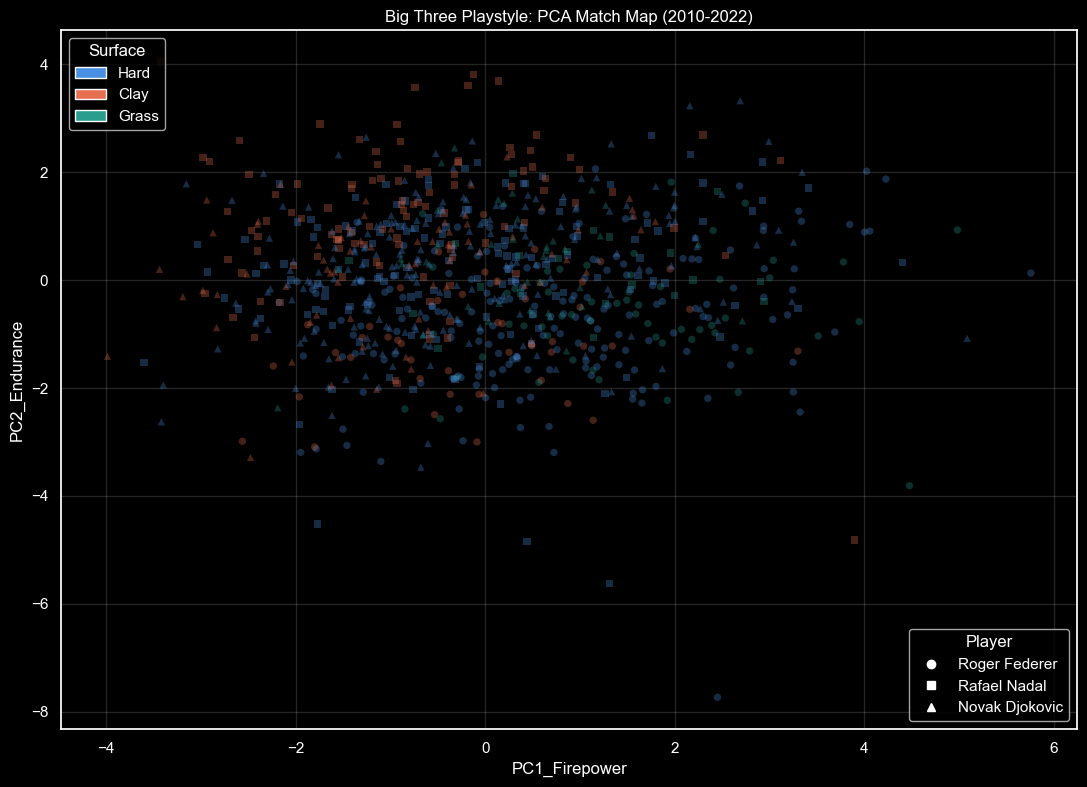

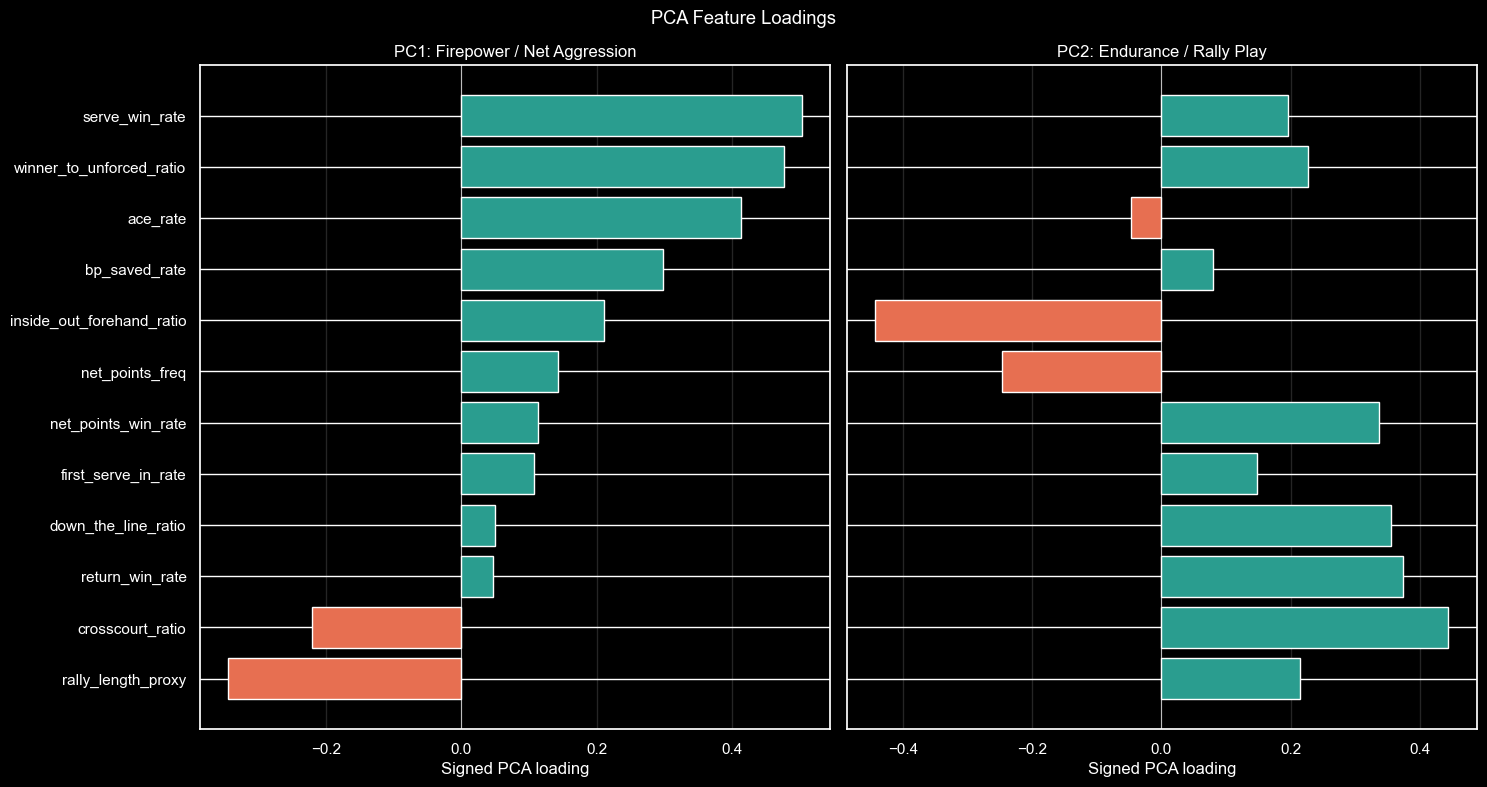

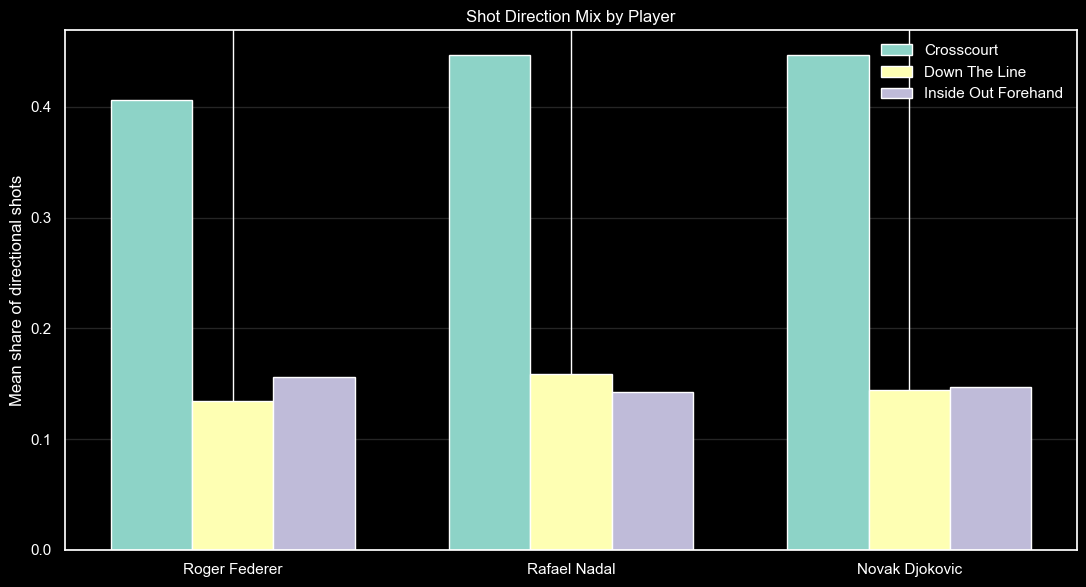

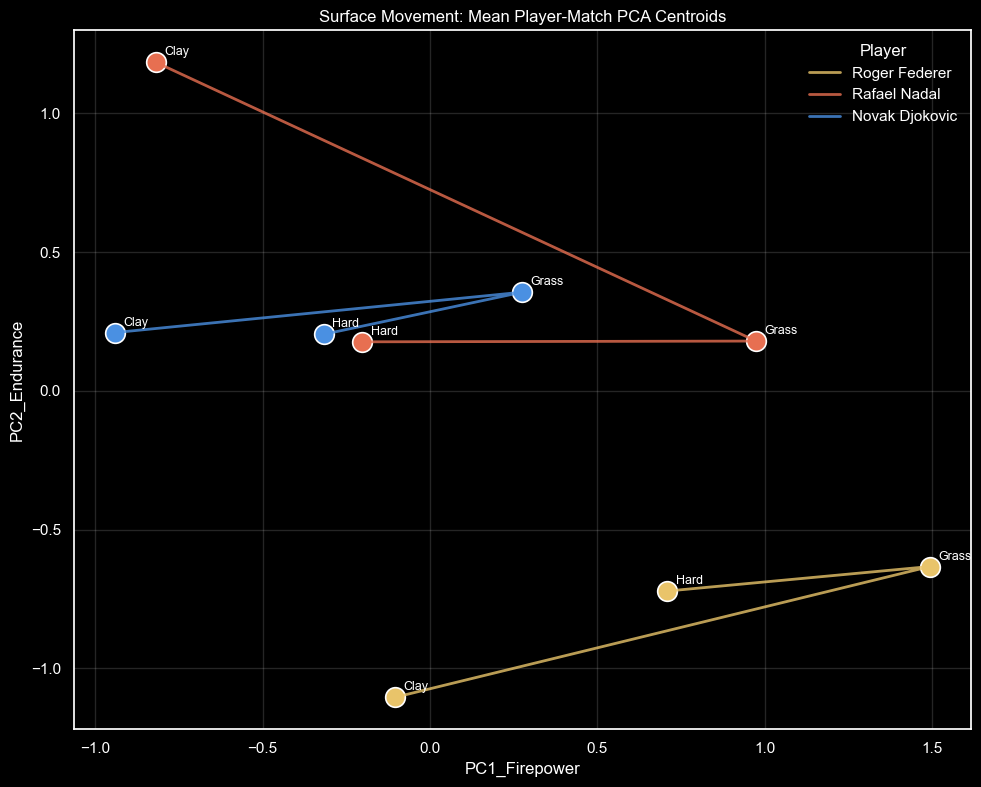

Roger Federer: Fast-court net attacker: a working interpretation emphasizing first-strike serving, attacking shot mix, and net play.
  Most common K-Means cluster: 2; contains 52% of this player's complete match rows.
  Archetype wording is interpretive, not a supervised model label or proof of a fixed style.

Rafael Nadal: Clay baseline counter-puncher: a working interpretation emphasizing surface context, return resilience, and rally patterns.
  Most common K-Means cluster: 1; contains 58% of this player's complete match rows.
  Archetype wording is interpretive, not a supervised model label or proof of a fixed style.

Novak Djokovic: All-court neutralizer: a working interpretation emphasizing return performance, balanced defense, and adaptability.
  Most common K-Means cluster: 1; contains 46% of this player's complete match rows.
  Archetype wording is interpretive, not a supervised model label or proof of a fixed style.


Saved goat_web_payload.json
Retained 857 complete player-ma

In [51]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

plt.style.use("dark_background")

# Use the report table when available; otherwise use the existing notebook variable.
if "report_tables" in globals() and "master_player_match" in report_tables:
    source_df = report_tables["master_player_match"].copy()
elif "master_player_match" in globals():
    source_df = master_player_match.copy()
else:
    raise NameError("Run the Data Merging report first to create master_player_match.")

BIG_THREE = ["Roger Federer", "Rafael Nadal", "Novak Djokovic"]
SURFACES = ["Hard", "Clay", "Grass"]
SURFACE_COLORS = {"Clay": "#E76F51", "Grass": "#2A9D8F", "Hard": "#4A90E2"}
PLAYER_MARKERS = {"Roger Federer": "o", "Rafael Nadal": "s", "Novak Djokovic": "^"}
PLAYER_COLORS = {"Roger Federer": "#E9C46A", "Rafael Nadal": "#E76F51", "Novak Djokovic": "#4A90E2"}

# Resolve both the current prefixed merge names and the simpler names in the analysis specification.
column_aliases = {
    "first_won": ["first_won"],
    "second_won": ["second_won"],
    "first_in": ["first_in"],
    "second_in": ["second_in"],
    "aces": ["aces"],
    "return_pts_won": ["return_pts_won"],
    "return_pts": ["return_pts"],
    "bp_saved": ["bp_saved"],
    "bk_pts": ["bk_pts"],
    "net_points": ["net_points_net_pts", "net_points__net_pts"],
    "net_points_won": ["net_points_pts_won", "net_points__pts_won"],
    "winners": ["winners"],
    "unforced": ["unforced"],
    "shot_crosscourt": ["shot_direction_crosscourt", "shot_direction__crosscourt"],
    "shot_middle": ["shot_direction_down_middle", "shot_direction__down_middle"],
    "shot_line": ["shot_direction_down_the_line", "shot_direction__down_the_line"],
    "shot_inside_out": ["shot_direction_inside_out", "shot_direction__inside_out"],
    "shot_inside_in": ["shot_direction_inside_in", "shot_direction__inside_in"],
    "return_shots": ["return_outcomes_total_shots", "return_outcomes__total_shots"],
    "return_outcome_points": ["return_outcomes_pts", "return_outcomes__pts"],
}

def resolve_column(frame, aliases):
    for candidate in aliases:
        if candidate in frame.columns:
            return candidate
    raise KeyError(f"Could not find any of these required columns: {aliases}")

resolved = {name: resolve_column(source_df, names) for name, names in column_aliases.items()}
analysis = source_df.copy()
analysis["match_date"] = pd.to_datetime(analysis["match_date"], errors="coerce")
analysis["year"] = analysis["match_date"].dt.year
analysis["surface"] = analysis["surface"].astype(str).str.strip().str.title()
analysis["surface"] = analysis["surface"].replace(
    {"Hard Court": "Hard", "Grass Court": "Grass", "Clay Court": "Clay"}
 )
analysis = analysis[
    analysis["player"].isin(BIG_THREE)
    & analysis["surface"].isin(SURFACES)
    & analysis["year"].between(2010, 2022)
].copy()

numeric_sources = list(resolved.values()) + ["points_played"]
for column in numeric_sources:
    analysis[column] = pd.to_numeric(analysis[column], errors="coerce")

total_directional_shots = (
    analysis[resolved["shot_crosscourt"]]
    + analysis[resolved["shot_middle"]]
    + analysis[resolved["shot_line"]]
    + analysis[resolved["shot_inside_out"]]
    + analysis[resolved["shot_inside_in"]]
 )
service_attempts = analysis["first_in"] + analysis["second_in"]

analysis["serve_win_rate"] = (analysis["first_won"] + analysis["second_won"]) / service_attempts.replace(0, np.nan)
analysis["ace_rate"] = analysis["aces"] / service_attempts.replace(0, np.nan)
analysis["first_serve_in_rate"] = analysis["first_in"] / service_attempts.replace(0, np.nan)
analysis["return_win_rate"] = analysis["return_pts_won"] / analysis["return_pts"].replace(0, np.nan)
analysis["bp_saved_rate"] = analysis["bp_saved"] / analysis["bk_pts"].replace(0, np.nan)
analysis["net_points_freq"] = analysis[resolved["net_points"]] / analysis["points_played"].replace(0, np.nan)
analysis["net_points_win_rate"] = analysis[resolved["net_points_won"]] / analysis[resolved["net_points"]].replace(0, np.nan)
analysis["winner_to_unforced_ratio"] = analysis[resolved["winners"]] / analysis[resolved["unforced"]].replace(0, np.nan)
analysis["inside_out_forehand_ratio"] = analysis[resolved["shot_inside_out"]] / total_directional_shots.replace(0, np.nan)
analysis["down_the_line_ratio"] = analysis[resolved["shot_line"]] / total_directional_shots.replace(0, np.nan)
analysis["crosscourt_ratio"] = analysis[resolved["shot_crosscourt"]] / total_directional_shots.replace(0, np.nan)
analysis["rally_length_proxy"] = analysis[resolved["return_shots"]] / analysis[resolved["return_outcome_points"]].replace(0, np.nan)

feature_cols = [
    "serve_win_rate",
    "ace_rate",
    "first_serve_in_rate",
    "return_win_rate",
    "bp_saved_rate",
    "net_points_freq",
    "net_points_win_rate",
    "winner_to_unforced_ratio",
    "inside_out_forehand_ratio",
    "down_the_line_ratio",
    "crosscourt_ratio",
    "rally_length_proxy",
 ]
analysis[feature_cols] = analysis[feature_cols].replace([np.inf, -np.inf], np.nan)
analysis = analysis.dropna(subset=feature_cols + ["player", "surface", "match_id"]).reset_index(drop=True)

if len(analysis) < 3:
    raise ValueError(f"Only {len(analysis)} complete match rows remain; PCA and 3-cluster models need at least 3.")
if analysis["player"].nunique() != 3:
    raise ValueError(f"Expected all three players after feature filtering; found {analysis['player'].unique().tolist()}.")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(analysis[feature_cols])
pca = PCA(n_components=2, random_state=42)
pca_scores = pca.fit_transform(X_scaled)
pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_cols,
    columns=["PC1_Firepower", "PC2_Endurance"],
 )

# PCA component signs are arbitrary; orient each axis toward its named interpretation.
axis_anchors = {
    "PC1_Firepower": ["serve_win_rate", "ace_rate", "net_points_freq", "inside_out_forehand_ratio"],
    "PC2_Endurance": ["return_win_rate", "crosscourt_ratio", "rally_length_proxy"],
 }
for axis, anchors in axis_anchors.items():
    if pca_loadings.loc[anchors, axis].mean() < 0:
        pca_loadings[axis] *= -1
        pca_scores[:, pca_loadings.columns.get_loc(axis)] *= -1

analysis["PC1_Firepower"] = pca_scores[:, 0]
analysis["PC2_Endurance"] = pca_scores[:, 1]

# Cluster on all 12 standardized features; PCA is a two-dimensional visualization, not the clustering input.
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
analysis["cluster_kmeans"] = kmeans.fit_predict(X_scaled)
gmm = GaussianMixture(n_components=3, random_state=42)
analysis["cluster_gmm"] = gmm.fit_predict(X_scaled)

pca_loadings.index.name = "feature"
pca_loadings = pca_loadings.reset_index()
feature_contributions = pca_loadings.copy()
feature_contributions["PC1_abs_contribution"] = feature_contributions["PC1_Firepower"].abs()
feature_contributions["PC2_abs_contribution"] = feature_contributions["PC2_Endurance"].abs()
player_cluster_summary = (
    analysis.groupby(["player", "cluster_kmeans"], as_index=False)
    .size()
    .rename(columns={"size": "matches"})
 )
player_cluster_summary["player_cluster_share"] = player_cluster_summary["matches"] / player_cluster_summary.groupby("player")["matches"].transform("sum")
cluster_counts = analysis["cluster_kmeans"].value_counts()
silhouette = silhouette_score(X_scaled, analysis["cluster_kmeans"]) if 1 < len(cluster_counts) < len(analysis) else np.nan
kmeans_gmm_ari = adjusted_rand_score(analysis["cluster_kmeans"], analysis["cluster_gmm"])

print(f"Complete cohort: {len(analysis):,} player-match rows; years 2010-2022; surfaces Hard, Clay, Grass.")
print(f"PCA explained variance: PC1={pca.explained_variance_ratio_[0]:.1%}, PC2={pca.explained_variance_ratio_[1]:.1%}.")
print(f"K-Means silhouette (12-feature standardized space): {silhouette:.3f}; K-Means/GMM adjusted Rand index: {kmeans_gmm_ari:.3f}.")
print("Cluster labels are arbitrary; these diagnostics show structure/consistency, not proof of intrinsic player archetypes.")
print("\nK-Means cluster composition:")
print(player_cluster_summary.to_string(index=False))
print("\nPCA loadings:")
print(pca_loadings.to_string(index=False))

# Plot 1: Match-level PCA scatter, encoding surface by color and player by marker.
fig, ax = plt.subplots(figsize=(11, 8))
for player in BIG_THREE:
    for surface in SURFACES:
        subset = analysis[(analysis["player"] == player) & (analysis["surface"] == surface)]
        if not subset.empty:
            ax.scatter(
                subset["PC1_Firepower"],
                subset["PC2_Endurance"],
                color=SURFACE_COLORS[surface],
                marker=PLAYER_MARKERS[player],
                alpha=0.3,
                s=28,
                edgecolors="none",
            )
ax.set_title("Big Three Playstyle: PCA Match Map (2010-2022)")
ax.set_xlabel("PC1_Firepower")
ax.set_ylabel("PC2_Endurance")
ax.grid(alpha=0.15)
surface_handles = [Patch(facecolor=SURFACE_COLORS[surface], label=surface) for surface in SURFACES]
player_handles = [Line2D([0], [0], marker=PLAYER_MARKERS[player], color="white", linestyle="", label=player) for player in BIG_THREE]
surface_legend = ax.legend(handles=surface_handles, title="Surface", loc="upper left")
ax.add_artist(surface_legend)
ax.legend(handles=player_handles, title="Player", loc="lower right")
fig.tight_layout()
plt.show()

# Plot 2: Signed PCA loadings explain the mathematical axis contributions.
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=True)
for ax, component, title in zip(
    axes,
    ["PC1_Firepower", "PC2_Endurance"],
    ["PC1: Firepower / Net Aggression", "PC2: Endurance / Rally Play"],
 ):
    ordered = pca_loadings.sort_values(component)
    colors = ["#2A9D8F" if value >= 0 else "#E76F51" for value in ordered[component]]
    ax.barh(ordered["feature"], ordered[component], color=colors)
    ax.axvline(0, color="white", linewidth=0.8, alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel("Signed PCA loading")
    ax.grid(axis="x", alpha=0.15)
fig.suptitle("PCA Feature Loadings")
fig.tight_layout()
plt.show()

# Plot 3: Mean shot-direction shares by player.
shot_features = ["crosscourt_ratio", "down_the_line_ratio", "inside_out_forehand_ratio"]
shot_means = analysis.groupby("player")[shot_features].mean().reindex(BIG_THREE)
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(BIG_THREE))
bar_width = 0.24
for index, feature in enumerate(shot_features):
    ax.bar(
        x + (index - 1) * bar_width,
        shot_means[feature].to_numpy(),
        width=bar_width,
        label=feature.replace("_ratio", "").replace("_", " ").title(),
    )
ax.set_xticks(x)
ax.set_xticklabels(BIG_THREE)
ax.set_ylabel("Mean share of directional shots")
ax.set_title("Shot Direction Mix by Player")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.15)
fig.tight_layout()
plt.show()

# Plot 4: Surface centroids and player-specific movement across surfaces.
centroids = (
    analysis.groupby(["player", "surface"], as_index=False)
    .agg(PC1_Firepower=("PC1_Firepower", "mean"), PC2_Endurance=("PC2_Endurance", "mean"), matches=("match_id", "nunique"))
 )
fig, ax = plt.subplots(figsize=(10, 8))
for player in BIG_THREE:
    subset = centroids[centroids["player"] == player].set_index("surface").reindex(["Clay", "Grass", "Hard"]).dropna(subset=["PC1_Firepower", "PC2_Endurance"])
    if subset.empty:
        continue
    ax.plot(subset["PC1_Firepower"], subset["PC2_Endurance"], color=PLAYER_COLORS[player], linewidth=2, alpha=0.8, label=player)
    ax.scatter(subset["PC1_Firepower"], subset["PC2_Endurance"], s=200, color=PLAYER_COLORS[player], edgecolor="white", linewidth=1.2)
    for surface, point in subset.iterrows():
        ax.annotate(surface, (point["PC1_Firepower"], point["PC2_Endurance"]), xytext=(6, 5), textcoords="offset points", fontsize=9)
ax.set_title("Surface Movement: Mean Player-Match PCA Centroids")
ax.set_xlabel("PC1_Firepower")
ax.set_ylabel("PC2_Endurance")
ax.legend(title="Player", frameon=False)
ax.grid(alpha=0.15)
fig.tight_layout()
plt.show()

def generate_executive_insights(results, cluster_table):
    archetype_text = {
        "Roger Federer": "Fast-court net attacker: a working interpretation emphasizing first-strike serving, attacking shot mix, and net play.",
        "Rafael Nadal": "Clay baseline counter-puncher: a working interpretation emphasizing surface context, return resilience, and rally patterns.",
        "Novak Djokovic": "All-court neutralizer: a working interpretation emphasizing return performance, balanced defense, and adaptability.",
    }
    cards = []
    for player in BIG_THREE:
        player_rows = cluster_table[cluster_table["player"] == player]
        if player_rows.empty:
            modal_cluster, cluster_share = None, None
        else:
            modal = player_rows.sort_values("player_cluster_share", ascending=False).iloc[0]
            modal_cluster = int(modal["cluster_kmeans"])
            cluster_share = float(modal["player_cluster_share"])
        card = {
            "player": player,
            "working_archetype": archetype_text[player],
            "modal_kmeans_cluster": modal_cluster,
            "share_of_player_matches_in_modal_cluster": cluster_share,
            "model_scope": "Exploratory clustering of charted player-matches from 2010-2022 across Hard, Clay, and Grass.",
            "caveat": "Archetype wording is interpretive, not a supervised model label or proof of a fixed style.",
        }
        cards.append(card)
        share_text = f"{cluster_share:.0%}" if cluster_share is not None else "not available"
        print(f"{player}: {card['working_archetype']}")
        print(f"  Most common K-Means cluster: {modal_cluster}; contains {share_text} of this player's complete match rows.")
        print(f"  {card['caveat']}\n")
    return cards

executive_cards = generate_executive_insights(analysis, player_cluster_summary)

def json_safe(value):
    if value is None or pd.isna(value):
        return None
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, (pd.Timestamp,)):
        return value.isoformat()
    return value

scatter_columns = ["match_id", "player", "surface", "year", "PC1_Firepower", "PC2_Endurance", "cluster_kmeans", "cluster_gmm"]
pca_points_payload = [
    {key: json_safe(value) for key, value in row.items()}
    for row in analysis[scatter_columns].to_dict(orient="records")
 ]
cluster_payload = [
    {key: json_safe(value) for key, value in row.items()}
    for row in player_cluster_summary.to_dict(orient="records")
 ]
loading_payload = [
    {key: json_safe(value) for key, value in row.items()}
    for row in pca_loadings.to_dict(orient="records")
 ]
goat_web_payload = {
    "metadata": {
        "title": "Big Three Playstyle Clustering",
        "cohort": BIG_THREE,
        "years": [2010, 2022],
        "surfaces": SURFACES,
        "complete_match_rows": int(len(analysis)),
        "pca_explained_variance_ratio": {
            "PC1_Firepower": float(pca.explained_variance_ratio_[0]),
            "PC2_Endurance": float(pca.explained_variance_ratio_[1]),
        },
        "kmeans_silhouette": json_safe(silhouette),
        "kmeans_gmm_adjusted_rand_index": float(kmeans_gmm_ari),
        "interpretation": "Exploratory associations; clustering does not prove intrinsic player archetypes.",
    },
    "pca_scatter_points": pca_points_payload,
    "cluster_assignments": cluster_payload,
    "pca_loadings": loading_payload,
    "executive_summary_cards": executive_cards,
}
with open("goat_web_payload.json", "w", encoding="utf-8") as payload_file:
    json.dump(goat_web_payload, payload_file, indent=2, allow_nan=False)

print("\nSaved goat_web_payload.json")
print(f"Retained {len(analysis):,} complete player-match rows from {analysis['match_id'].nunique():,} matches.")

## III. Spatial Shot-Zone Heatmaps (2005-Present)
Map charted categorical serve and shot-direction counts to representative court zones. Coordinates and jitter are synthetic zone-level visualizations, not observed ball-tracking trajectories.

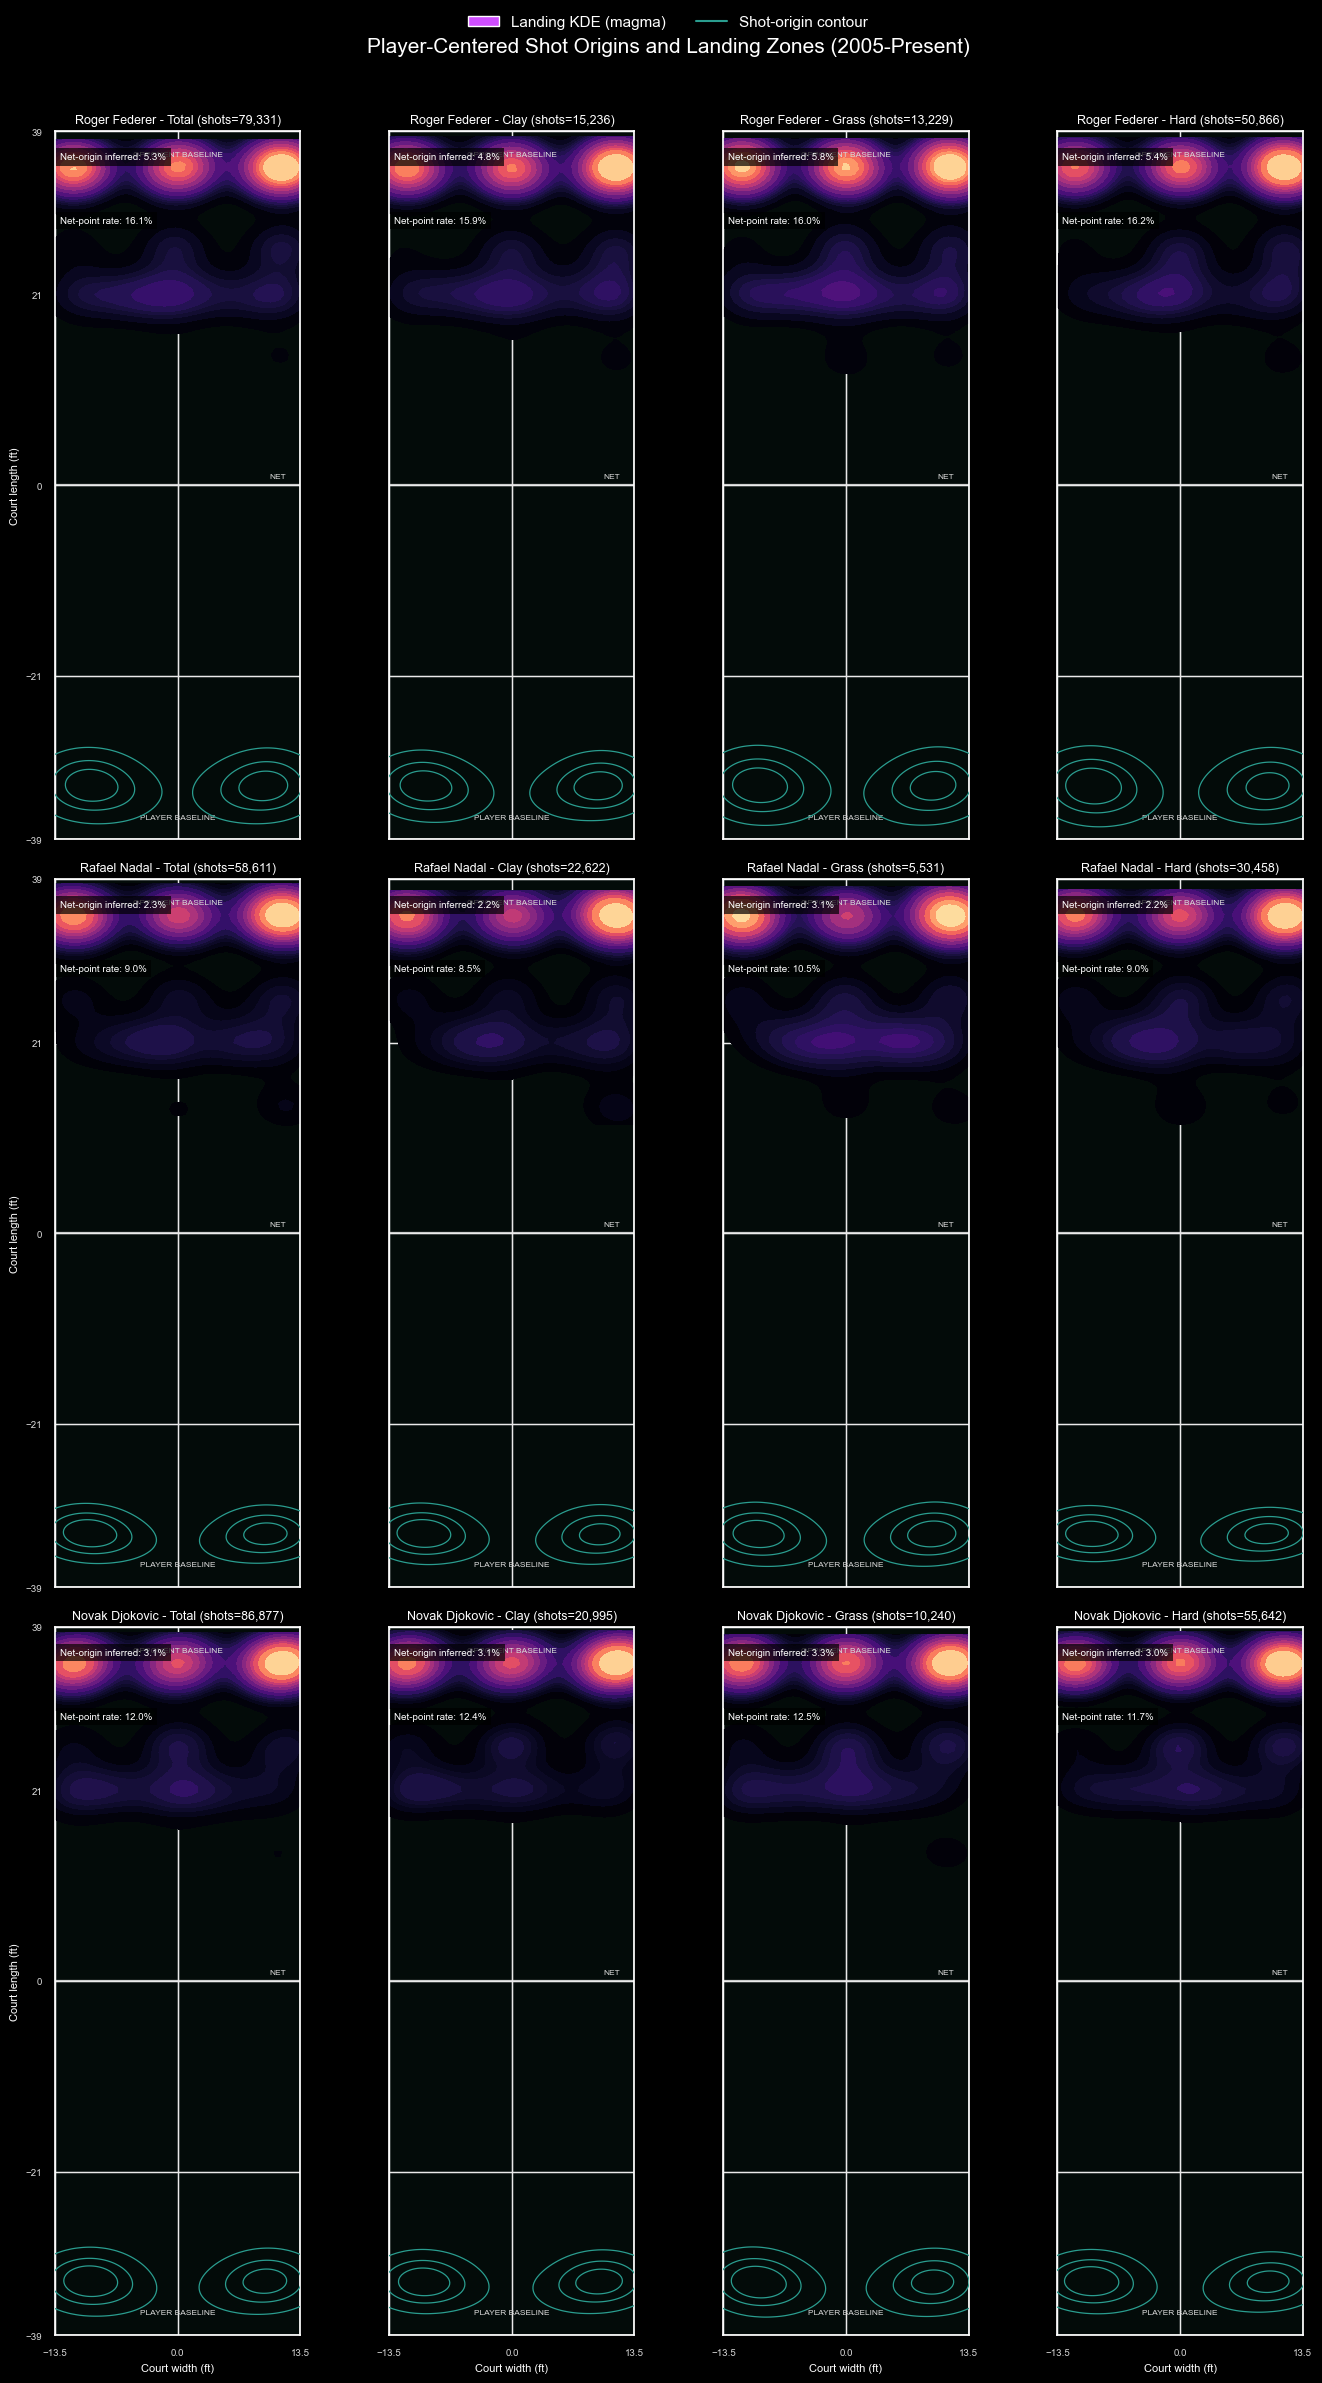

Player-centered parsed shot locations by player/surface:
        player surface  rally_shot_codes  directed_shots  left_handed_shots  direction_coverage  inferred_net_origin_share  net_point_frequency_actual  net_data_coverage  target_left_share  target_center_share  target_right_share
 Roger Federer   Total             79331           78010                  0            0.983348                   0.053397                    0.161188           1.000000           0.279772             0.317831            0.402397
 Roger Federer    Clay             15236           15072                  0            0.989236                   0.048438                    0.158888           1.000000           0.294122             0.321590            0.384289
 Roger Federer   Grass             13229           12671                  0            0.957820                   0.057601                    0.160348           1.000000           0.279299             0.324915            0.395786
 Roger Federer    Hard 

In [60]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import gaussian_kde

plt.style.use("dark_background")
BIG_THREE = ["Roger Federer", "Rafael Nadal", "Novak Djokovic"]
SURFACES = ["Total", "Clay", "Grass", "Hard"]
COURT_X, COURT_Y = (-39.0, 39.0), (-13.5, 13.5)
GRID_SIZE, MAX_KDE_SAMPLES = 20, 1800
SHOT_TYPES = set("fbrsvzopuylmhijktq")
NET_TYPES, FH_TYPES, BH_TYPES = set("vzophijk"), set("frvulhj"), set("bszymikp")
random_generator = np.random.default_rng(42)

required = ["charting_m_matches", "charting_m_stats_Overview", "charting_m_stats_NetPoints"]
point_keys = [key for key in raw_dataframes if key.lower().startswith("charting_m_points")]
missing = [key for key in required if key not in raw_dataframes]
if missing or not point_keys:
    raise KeyError(f"Missing required spatial source tables: {missing or 'point CSVs'}")

matches = raw_dataframes["charting_m_matches"].copy().rename(columns={
    "Player 1": "player1", "Player 2": "player2", "Pl 1 hand": "hand1",
    "Pl 2 hand": "hand2", "Date": "match_date", "Surface": "surface",
})
matches["match_date"] = pd.to_datetime(matches["match_date"].astype(str), format="%Y%m%d", errors="coerce")
matches["year"] = matches["match_date"].dt.year
latest_available_date = matches["match_date"].max()
matches["surface"] = matches["surface"].astype(str).str.strip().str.title().replace(
    {"Hard Court": "Hard", "Grass Court": "Grass", "Clay Court": "Clay"}
 )
match_metadata = matches[
    matches["match_date"].ge(pd.Timestamp("2005-01-01"))
    & matches["surface"].isin(["Hard", "Clay", "Grass"])
    & (matches["player1"].isin(BIG_THREE) | matches["player2"].isin(BIG_THREE))
 ][["match_id", "match_date", "year", "surface", "player1", "player2", "hand1", "hand2"]]
point_cols = ["match_id", "Pts", "Gm1", "Gm2", "TbSet", "Svr", "1st", "2nd"]
points = pd.concat([raw_dataframes[key][point_cols] for key in point_keys], ignore_index=True)
points = points.rename(columns={"1st": "first_sequence", "2nd": "second_sequence"})
points = points.merge(match_metadata, on="match_id", how="inner", validate="many_to_one")

def parse_shots(sequence):
    parsed, i = [], 0
    while i < len(sequence):
        if sequence[i] not in SHOT_TYPES:
            i += 1
            continue
        kind = sequence[i]
        i += 1
        modifiers = []
        while i < len(sequence) and sequence[i] in "+-=;^":
            modifiers.append(sequence[i])
            i += 1
        direction = depth = None
        if i < len(sequence) and sequence[i] in "0123":
            direction = int(sequence[i])
            i += 1
            if i < len(sequence) and sequence[i] in "789":
                depth = int(sequence[i])
                i += 1
        parsed.append((kind, modifiers, direction, depth))
    return parsed

def first_serve_code(sequence):
    for char in sequence:
        if char in SHOT_TYPES:
            break
        if char in "456":
            return int(char)
    return None

def score_value(value):
    return {"0": 0, "15": 1, "30": 2, "40": 3, "ad": 4, "a": 4}.get(str(value).strip().lower())

def serving_court(row):
    score = str(row.Pts).split("-")
    if len(score) != 2:
        return None
    tied = pd.to_numeric(row.Gm1, errors="coerce") == pd.to_numeric(row.Gm2, errors="coerce")
    games = pd.to_numeric(row.Gm1, errors="coerce")
    is_tb = str(row.TbSet).lower() in {"true", "1", "yes"} and tied and games >= 6 and all(part.strip().isdigit() for part in score)
    if is_tb:
        n = int(score[0]) + int(score[1])
        return "deuce" if n == 0 or ((n - 1) // 2) % 2 else "ad"
    left, right = score_value(score[0]), score_value(score[1])
    return None if left is None or right is None else ("deuce" if (left + right) % 2 == 0 else "ad")

def target_y(direction, target_side):
    return {1: -target_side * 11.5, 2: 0.0, 3: target_side * 11.5}.get(direction)

def target_hand_side(direction, hand):
    if direction not in {1, 3} or hand not in {"L", "R"}:
        return "unknown"
    forehand = (direction == 1 and hand == "R") or (direction == 3 and hand == "L")
    return "forehand" if forehand else "backhand"

def serve_landing_y(code, court):
    return {"deuce": {4: -11.0, 5: -6.0, 6: -1.5}, "ad": {4: 11.0, 5: 6.0, 6: 1.5}}.get(court, {}).get(code)

shot_rows, serve_rows, origin_rows = [], [], []
parse_coverage = {p: {"shot_codes": 0, "directed_shots": 0, "undirected_shots": 0, "left_hand_shots": 0, "explicit_net_markers": 0, "explicit_baseline_markers": 0} for p in BIG_THREE}

for row in points.itertuples(index=False):
    server_num = str(row.Svr).strip()
    if server_num not in {"1", "2"}:
        continue
    p1, p2 = row.player1, row.player2
    server, returner = (p1, p2) if server_num == "1" else (p2, p1)
    server_hand, returner_hand = (row.hand1, row.hand2) if server_num == "1" else (row.hand2, row.hand1)
    sequence = str(row.second_sequence or "").strip() or str(row.first_sequence or "").strip()
    serve_code, service_court = first_serve_code(sequence), serving_court(row)
    if server in BIG_THREE and serve_code in {4, 5, 6} and service_court:
        sy = serve_landing_y(serve_code, service_court)
        origin_y = 6.0 if service_court == "deuce" else -6.0
        serve_rows.append({"player": server, "surface": row.surface, "year": int(row.year), "x_ft": 21.0, "y_ft": sy, "event_type": "serve", "match_id": row.match_id})
        origin_rows.append({"player": server, "surface": row.surface, "x_ft": -34.0, "y_ft": origin_y, "event_type": "serve", "match_id": row.match_id})

    for shot_index, (kind, modifiers, direction, depth) in enumerate(parse_shots(sequence)):
        hitter, target = (returner, server) if shot_index % 2 == 0 else (server, returner)
        hitter_hand, target_hand = (returner_hand, server_hand) if hitter == returner else (server_hand, returner_hand)
        if hitter not in BIG_THREE:
            continue
        stats = parse_coverage[hitter]
        stats["shot_codes"] += 1
        stats["left_hand_shots"] += int(hitter_hand == "L")
        if "-" in modifiers:
            at_net = True
            stats["explicit_net_markers"] += 1
        elif "=" in modifiers:
            at_net = False
            stats["explicit_baseline_markers"] += 1
        else:
            at_net = kind in NET_TYPES

        hitter_side = 1 if hitter == returner else -1
        target_side = -hitter_side
        view_rotation = 1 if hitter == server else -1
        if kind in FH_TYPES and hitter_hand in {"L", "R"}:
            hitter_fh_y = -hitter_side * (1 if hitter_hand == "R" else -1) * 10.0
            origin_y = hitter_fh_y
        elif kind in BH_TYPES and hitter_hand in {"L", "R"}:
            hitter_fh_y = -hitter_side * (1 if hitter_hand == "R" else -1) * 10.0
            origin_y = -hitter_fh_y
        else:
            origin_y = 0.0
        origin_x = -abs(4.5 if at_net else 33.0)
        origin_rows.append({"player": hitter, "surface": row.surface, "x_ft": origin_x, "y_ft": origin_y * view_rotation, "event_type": "rally shot", "match_id": row.match_id, "hitter_hand": hitter_hand})
        if direction not in {1, 2, 3}:
            stats["undirected_shots"] += 1
            continue
        stats["directed_shots"] += 1
        depth_x = {7: 14.0, 8: 26.0, 9: 35.0}.get(depth, 35.0)
        shot_rows.append({
            "player": hitter, "surface": row.surface, "year": int(row.year), "match_id": row.match_id,
            "shot_type": kind, "hitter_hand": hitter_hand, "target": target, "target_hand": target_hand,
            "direction_code": direction, "target_hand_side": target_hand_side(direction, target_hand),
            "depth_code": depth, "x_ft": abs(depth_x), "y_ft": target_y(direction, target_side) * view_rotation,
        })

shot_events, serve_events, origin_events = pd.DataFrame(shot_rows), pd.DataFrame(serve_rows), pd.DataFrame(origin_rows)
landing_events = pd.concat([shot_events, serve_events], ignore_index=True, sort=False)
if landing_events.empty or origin_events.empty:
    raise ValueError("No point-sequence shot/serve locations could be decoded.")

def jitter_sample(data, x_col, y_col):
    if data.empty:
        return pd.DataFrame(columns=["x", "y"])
    n = min(len(data), MAX_KDE_SAMPLES)
    sampled = data.sample(n=n, replace=False, random_state=42)
    return pd.DataFrame({"x": np.clip(sampled[x_col].to_numpy() + random_generator.normal(0, 1.2, n), *COURT_Y), "y": np.clip(sampled[y_col].to_numpy() + random_generator.normal(0, 1.0, n), *COURT_X)})

def make_grid(data):
    x_edges, y_edges = np.linspace(*COURT_Y, GRID_SIZE + 1), np.linspace(*COURT_X, GRID_SIZE + 1)
    if len(data) < 3:
        return np.zeros((GRID_SIZE, GRID_SIZE))
    gx, gy = np.meshgrid((x_edges[:-1] + x_edges[1:]) / 2, (y_edges[:-1] + y_edges[1:]) / 2)
    try:
        grid = gaussian_kde(np.vstack([data["x"], data["y"]]))(np.vstack([gx.ravel(), gy.ravel()])).reshape(GRID_SIZE, GRID_SIZE)
    except (ValueError, np.linalg.LinAlgError):
        grid = np.histogram2d(data["y"], data["x"], bins=[y_edges, x_edges])[0]
    return grid / grid.sum() if grid.sum() else grid

def draw_court(ax):
    color = "#E8E8E8"
    ax.axvspan(*COURT_Y, color="#123B31", alpha=0.2, zorder=0)
    for y in [-39, -21, 0, 21, 39]:
        ax.axhline(y, color=color, linewidth=1.6 if y == 0 else 0.8, alpha=0.85, zorder=1)
    for x in [-13.5, 0, 13.5]:
        ax.axvline(x, color=color, linewidth=0.8, alpha=0.85, zorder=1)
    ax.vlines(0, -21, 21, color=color, linewidth=0.8, alpha=0.9, zorder=1)
    ax.set_xlim(*COURT_Y)
    ax.set_ylim(*COURT_X)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xticks([-13.5, 0, 13.5])
    ax.set_yticks([-39, -21, 0, 21, 39])
    ax.tick_params(labelsize=7, colors="#D8D8D8")
    ax.text(0, -36.5, "PLAYER BASELINE", ha="center", va="center", fontsize=6, color="#D8D8D8")
    ax.text(0, 36.5, "OPPONENT BASELINE", ha="center", va="center", fontsize=6, color="#D8D8D8")
    ax.text(11.0, 0.7, "NET", ha="center", va="bottom", fontsize=6, color="#D8D8D8")

overview = raw_dataframes["charting_m_stats_Overview"].copy()
overview = overview[overview["player"].isin(BIG_THREE) & overview["set"].astype(str).str.lower().eq("total")]
overview = overview.merge(match_metadata, on="match_id", how="inner", validate="many_to_one")
overview["player_points"] = pd.to_numeric(overview["serve_pts"], errors="coerce") + pd.to_numeric(overview["return_pts"], errors="coerce")
overview_matches = overview.groupby(["player", "surface"], as_index=False).agg(overview_matches=("match_id", "nunique"))
net_stats = raw_dataframes["charting_m_stats_NetPoints"].copy()
net_stats = net_stats[net_stats["player"].isin(BIG_THREE) & net_stats["row"].astype(str).str.lower().eq("netpoints")]
net_stats = net_stats.merge(match_metadata, on="match_id", how="inner", validate="many_to_one")
net_stats["net_points"] = pd.to_numeric(net_stats["net_pts"], errors="coerce").fillna(0)
net_matches = overview[["match_id", "player", "surface", "player_points"]].merge(net_stats[["match_id", "player", "net_points"]], on=["match_id", "player"], how="inner", validate="one_to_one")
net_summary = net_matches.groupby(["player", "surface"], as_index=False).agg(net_points=("net_points", "sum"), player_points=("player_points", "sum"), matches_with_net_data=("match_id", "nunique"))
net_summary = net_summary.merge(overview_matches, on=["player", "surface"], how="left")
net_summary["net_point_frequency"] = net_summary["net_points"] / net_summary["player_points"].replace(0, np.nan)
net_summary["net_data_coverage"] = net_summary["matches_with_net_data"] / net_summary["overview_matches"].replace(0, np.nan)

def net_activity_for(player, surface):
    data = net_summary[net_summary["player"] == player]
    if surface != "Total": data = data[data["surface"] == surface]
    if data.empty: return {"net_point_frequency": np.nan, "net_data_coverage": np.nan, "net_points": 0, "player_points": 0}
    net_points, player_points = data["net_points"].sum(), data["player_points"].sum()
    net_rows, overview_rows = data["matches_with_net_data"].sum(), data["overview_matches"].sum()
    return {"net_point_frequency": net_points / player_points if player_points else np.nan, "net_data_coverage": net_rows / overview_rows if overview_rows else np.nan, "net_points": int(net_points), "player_points": int(player_points), "matches_with_net_data": int(net_rows), "overview_matches": int(overview_rows)}

conditions, landing_samples, origin_samples, summary_rows = {}, {}, {}, []
spatial_heatmaps_2005_present = {"metadata": {
    "period_start": "2005-01-01", "latest_available_match_date": latest_available_date.strftime("%Y-%m-%d"),
    "players": BIG_THREE, "surfaces": SURFACES, "coordinate_units": "feet",
    "coordinate_system": {"net_x": 0, "server_baseline_x": -39, "receiver_baseline_x": 39, "singles_sidelines_y": [-13.5, 13.5], "center_line_y": 0},
    "plot_orientation": "Vertical court; x-axis is width/Y, y-axis is length/X; player is normalized to the server baseline and receiver to the opposite end.",
    "direction_semantics": "Digits 1/2/3 target opponent right/center/left; target hand labels forehand/backhand side.",
    "position_semantics": "Workbook defaults and explicit -/= markers infer shot origins.",
    "depth_semantics": "7/8/9 map service-box/mid/deep return zones; absent depth is projected baseline crossing.",
    "interpretation": "Point-code reconstructed proxies, not tracking coordinates; defaults and missing depths are estimates.",
    "jitter": {"x_sigma_ft": 1.2, "y_sigma_ft": 1.0, "synthetic": True}, "grid_size": [GRID_SIZE, GRID_SIZE],
}, "conditions": conditions, "parse_coverage": parse_coverage}

for player in BIG_THREE:
    for surface in SURFACES:
        key = f"{player}|{surface}"
        land = landing_events[landing_events["player"] == player]
        origin = origin_events[origin_events["player"] == player]
        shots = shot_events[shot_events["player"] == player]
        if surface != "Total":
            land = land[land["surface"] == surface]; origin = origin[origin["surface"] == surface]; shots = shots[shots["surface"] == surface]
        land_sample = jitter_sample(land, "y_ft", "x_ft")
        origin_sample = jitter_sample(origin, "y_ft", "x_ft")
        landing_samples[key], origin_samples[key] = land_sample, origin_sample
        rally_origins = origin[origin["event_type"] == "rally shot"]
        net_origin_count = int((rally_origins["x_ft"].abs() < 10).sum())
        net_origin_share = net_origin_count / len(rally_origins) if len(rally_origins) else np.nan
        activity = net_activity_for(player, surface)
        left_share = float((shots["y_ft"] < 0).mean()) if len(shots) else np.nan
        center_share = float((shots["y_ft"] == 0).mean()) if len(shots) else np.nan
        right_share = float((shots["y_ft"] > 0).mean()) if len(shots) else np.nan
        serve_count = int(land["event_type"].eq("serve").sum())
        details = {
            "player": player, "surface": surface, "rally_shot_count": int(len(rally_origins)), "direction_coded_shots": int(len(shots)),
            "serve_count": serve_count, "left_handed_shots": int(rally_origins["hitter_hand"].eq("L").sum()),
            "inferred_net_origin_shots": net_origin_count, "inferred_net_origin_share": net_origin_share,
            "target_left_share": left_share, "target_center_share": center_share, "target_right_share": right_share,
            "net_activity_proxy": activity, "landing_grid": make_grid(land_sample).tolist(), "origin_grid": make_grid(origin_sample).tolist(), "grid": make_grid(land_sample).tolist(),
            "grid_x_edges_ft": np.linspace(*COURT_Y, GRID_SIZE + 1).tolist(), "grid_y_edges_ft": np.linspace(*COURT_X, GRID_SIZE + 1).tolist(),
            "bounding_box_ft": {"x_min": COURT_Y[0], "x_max": COURT_Y[1], "y_min": COURT_X[0], "y_max": COURT_X[1]},
            "visual_jitter_points": {"landing": int(len(land_sample)), "origin": int(len(origin_sample))}, "synthetic_jitter": True,
        }
        conditions[key] = details
        summary_rows.append({"player": player, "surface": surface, "rally_shot_codes": len(rally_origins), "directed_shots": len(shots),
            "left_handed_shots": details["left_handed_shots"], "direction_coverage": len(shots) / len(rally_origins) if len(rally_origins) else np.nan,
            "inferred_net_origin_share": net_origin_share, "net_point_frequency_actual": activity["net_point_frequency"], "net_data_coverage": activity["net_data_coverage"],
            "target_left_share": left_share, "target_center_share": center_share, "target_right_share": right_share})

fig, axes = plt.subplots(3, 4, figsize=(14, 24), sharex=True, sharey=True)
for row_index, player in enumerate(BIG_THREE):
    for column_index, surface in enumerate(SURFACES):
        ax = axes[row_index, column_index]
        key = f"{player}|{surface}"
        land, origin, details = landing_samples[key], origin_samples[key], conditions[key]
        draw_court(ax)
        if len(land) >= 3 and land["x"].std() > 0 and land["y"].std() > 0:
            sns.kdeplot(data=land, x="x", y="y", cmap="magma", fill=True, thresh=0.05, levels=15, gridsize=50, cut=0, ax=ax, zorder=2)
        if len(origin) >= 10 and origin["x"].std() > 0 and origin["y"].std() > 0:
            sns.kdeplot(data=origin, x="x", y="y", color="#2A9D8F", levels=4, fill=False, linewidths=0.9, thresh=0.15, ax=ax, zorder=3)
        origin_rate, net_rate = details["inferred_net_origin_share"], details["net_activity_proxy"]["net_point_frequency"]
        origin_label = f"{origin_rate:.1%}" if pd.notna(origin_rate) else "n/a"
        net_label = f"{net_rate:.1%}" if pd.notna(net_rate) else "n/a"
        ax.set_title(f"{player} - {surface} (shots={details['rally_shot_count']:,})", fontsize=9)
        ax.text(0.02, 0.97, f"Net-origin inferred: {origin_label}", transform=ax.transAxes, va="top", ha="left", fontsize=7, bbox={"facecolor": "black", "alpha": 0.7, "edgecolor": "none", "pad": 3}, zorder=5)
        ax.text(0.02, 0.88, f"Net-point rate: {net_label}", transform=ax.transAxes, va="top", ha="left", fontsize=7, bbox={"facecolor": "black", "alpha": 0.7, "edgecolor": "none", "pad": 3}, zorder=5)
        if row_index == 2: ax.set_xlabel("Court width (ft)", fontsize=8)
        if column_index == 0: ax.set_ylabel("Court length (ft)", fontsize=8)
fig.legend(handles=[Patch(facecolor="#CF4DFF", label="Landing KDE (magma)"), Line2D([0], [0], color="#2A9D8F", label="Shot-origin contour")], loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.995))
fig.suptitle("Player-Centered Shot Origins and Landing Zones (2005-Present)", fontsize=15, y=0.98)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

spatial_style_summary = pd.DataFrame(summary_rows)
print("Player-centered parsed shot locations by player/surface:")
print(spatial_style_summary.to_string(index=False))
print("\nEach rally is rotated so the hitter is on the player/server baseline and the target is at the receiver end.")
print("Origins use workbook defaults and explicit position markers; missing depth is a projected baseline crossing, not measured landing depth.")

def json_safe_spatial(value):
    if isinstance(value, dict): return {str(k): json_safe_spatial(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)): return [json_safe_spatial(v) for v in value]
    if isinstance(value, (np.integer,)): return int(value)
    if isinstance(value, (np.floating, float)): return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_,)): return bool(value)
    return value

try:
    with open("goat_web_payload.json", "r", encoding="utf-8") as payload_file:
        goat_web_payload = json.load(payload_file)
except FileNotFoundError:
    goat_web_payload = {}
goat_web_payload["spatial_heatmaps_2005_present"] = json_safe_spatial(spatial_heatmaps_2005_present)
with open("goat_web_payload.json", "w", encoding="utf-8") as payload_file:
    json.dump(goat_web_payload, payload_file, indent=2, allow_nan=False)
print("Updated spatial heatmaps in goat_web_payload.json; existing payload keys were preserved.")

#### Court Plot Reading Guide
The plot below is player-centered: each hitter is normalized to the lower baseline, and the target is on the opposite half. Magma shows landing-zone KDE; teal contours show shot origins. Court coordinates are reconstructed from chart codes, not tracking data.

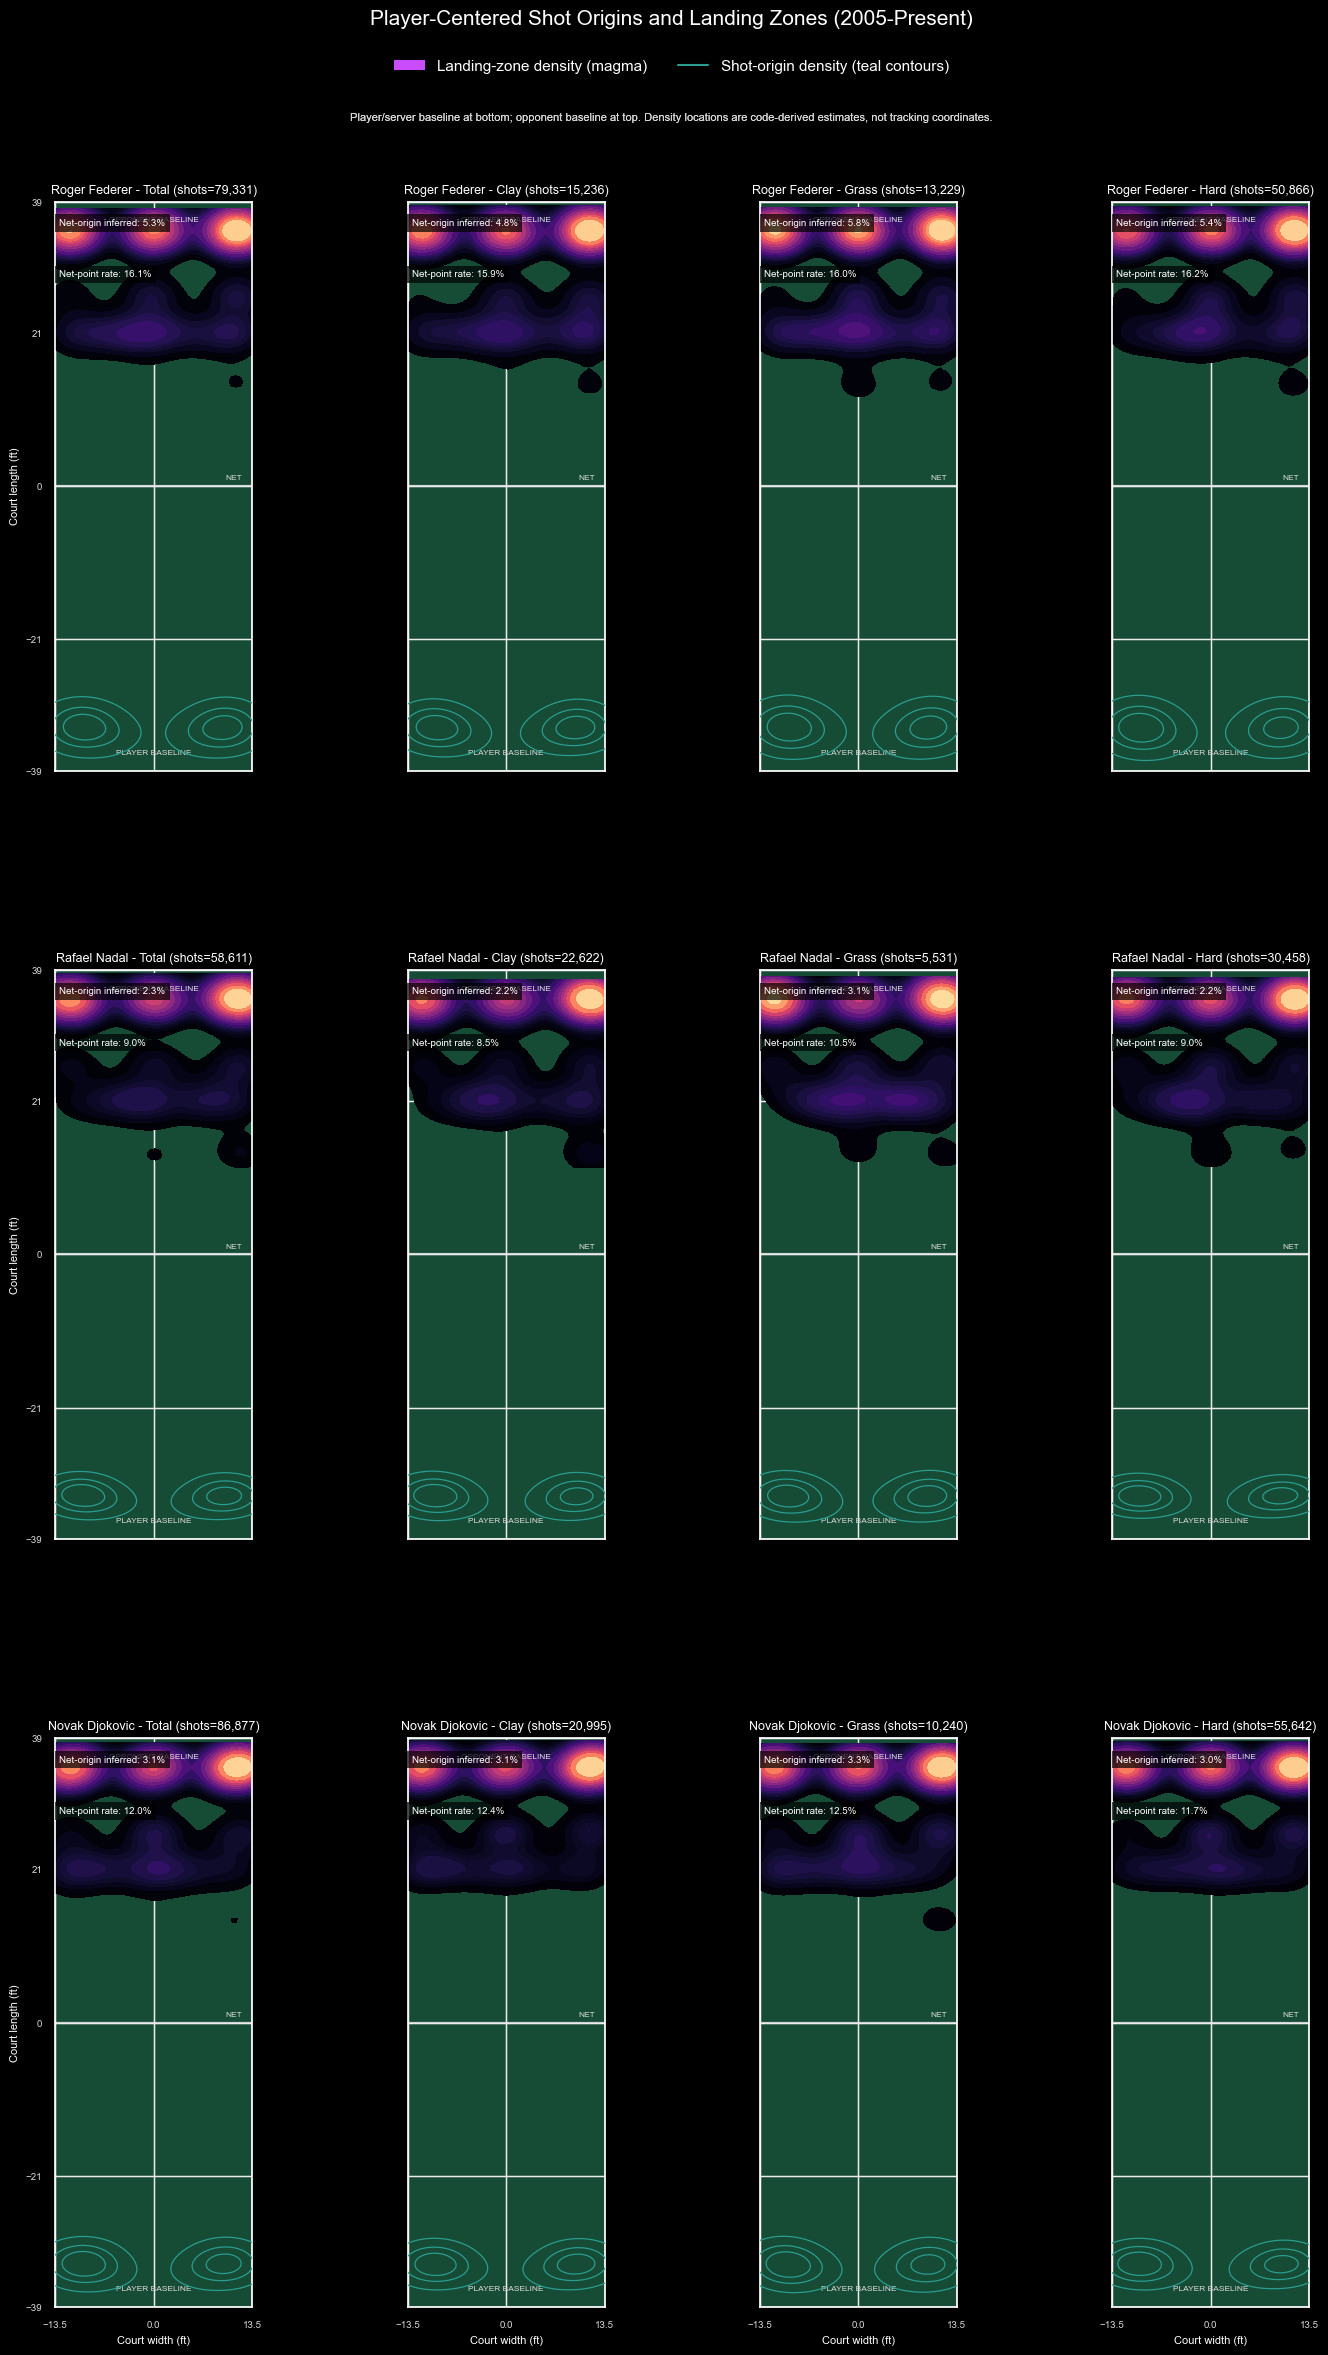

In [62]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

for court_ax in axes.flat:
    court_ax.set_facecolor("#0C1712")
    if court_ax.patches:
        court_patch = court_ax.patches[0]
        court_patch.set_facecolor("#1B6548")
        court_patch.set_edgecolor("#8EBBA6")
        court_patch.set_alpha(0.68)
        court_patch.set_linewidth(0.8)

for existing_legend in fig.legends:
    existing_legend.remove()
fig.legend(
    handles=[
        Patch(facecolor="#C94CFF", edgecolor="none", label="Landing-zone density (magma)"),
        Line2D([0], [0], color="#2A9D8F", linewidth=1.5, label="Shot-origin density (teal contours)"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.965),
    ncol=2,
    frameon=False,
 )
fig.text(
    0.5,
    0.935,
    "Player/server baseline at bottom; opponent baseline at top. Density locations are code-derived estimates, not tracking coordinates.",
    ha="center",
    va="center",
    fontsize=8,
    color="#D8D8D8",
 )
fig.subplots_adjust(top=0.90, hspace=0.35, wspace=0.22)
display(fig)

### How to Read the Spatial Maps
Each panel is one player and surface; Total pools the three surfaces. The court is vertical: horizontal is court width in feet (negative left, positive right); vertical is court length in feet (player/server baseline at -39, net at 0, opponent baseline at +39). The green rectangle and white lines are the court. Magma fill is estimated landing-zone density. The green/teal rings are KDE contours of inferred shot origins, not individual shot markers or measured tracking positions. Both layers appear because a shot has a start and destination. All rallies are rotated so the hitter is at the lower baseline; Nadal's left-handedness and the workbook's handedness-relative target digits are included.
### Interpretation
In the charted 2005-present sample, target-side shares are Federer 28.0% left / 31.8% middle / 40.2% right, Nadal 32.6% / 26.6% / 40.8%, and Djokovic 29.3% / 30.3% / 40.4%. For Nadal, middle shares are 25.1% on clay and 24.2% on grass, so these records do not support a higher down-the-middle share on grass. NetPoints frequency is a separate point-level measure: Federer 16.1%, Nadal 9.0%, Djokovic 12.0% overall. The dedicated SnV table records about 10.2% of Federer's charted service points as serve-and-volley points; this is not a lifetime estimate and is distinct from the percentage of all shot origins inferred near the net (about 5.3%).
These are reconstructed chart-data estimates, not tracking data. Most origin positions use workbook shot-type defaults, explicit net/baseline markers are uncommon, and missing return depth is projected to the baseline crossing. Results cover charted matches in these files, not every career match.

## Pressure & Clutch Survival Analysis
This section tests whether Federer, Nadal, and Djokovic differed in two charted high-pressure situations from 2005 onward: saving a break point while serving and winning an individual tiebreak point. The model treats each qualifying point as an observation and predicts whether the player succeeds. It accounts for player, surface, set number, whether the set is deciding, the shot count of the immediately preceding point, and a player-specific tiebreak adjustment; match-clustered uncertainty allows for multiple observations coming from the same match. We report odds ratios with 95% confidence intervals: an odds ratio describes odds, not a percentage chance. The charts show adjusted break-point-save odds and model-predicted break-point-save probability by set under a stated reference scenario. These are measures of on-court outcomes in the charted sample, not direct measurements of psychology or proof of cause.

,Variable / Player,Coefficient (beta),Odds Ratio,95% CI Lower,95% CI Upper,p-value,Significant (p < 0.05)
0,Break-point save odds: Roger Federer,0.7884,2.1999,2.0559,2.3540,2.57e-115,True
1,Tiebreak-specific odds shift: Roger Federer,-0.6574,0.5182,0.4780,0.5618,2.32e-57,True
2,Break-point save odds: Rafael Nadal,0.7174,2.0492,1.8957,2.2151,6.33e-73,True
3,Tiebreak-specific odds shift: Rafael Nadal,-0.6756,0.5089,0.4548,0.5694,5.03e-32,True
4,Break-point save odds: Novak Djokovic,0.6295,1.8767,1.7383,2.0261,2.27e-58,True
5,Tiebreak-specific odds shift: Novak Djokovic,-0.4681,0.6262,0.5649,0.6940,4.85e-19,True
6,Clay vs Hard surface,-0.0219,0.9783,0.9135,1.0478,0.531,False
7,Grass vs Hard surface,0.0985,1.1035,1.0195,1.1945,0.0147,True
8,Each additional set (vs set 1),0.0050,1.0050,0.9774,1.0334,0.725,False
9,Each additional shot in preceding point,-0.0039,0.9961,0.9901,1.0022,0.21,False


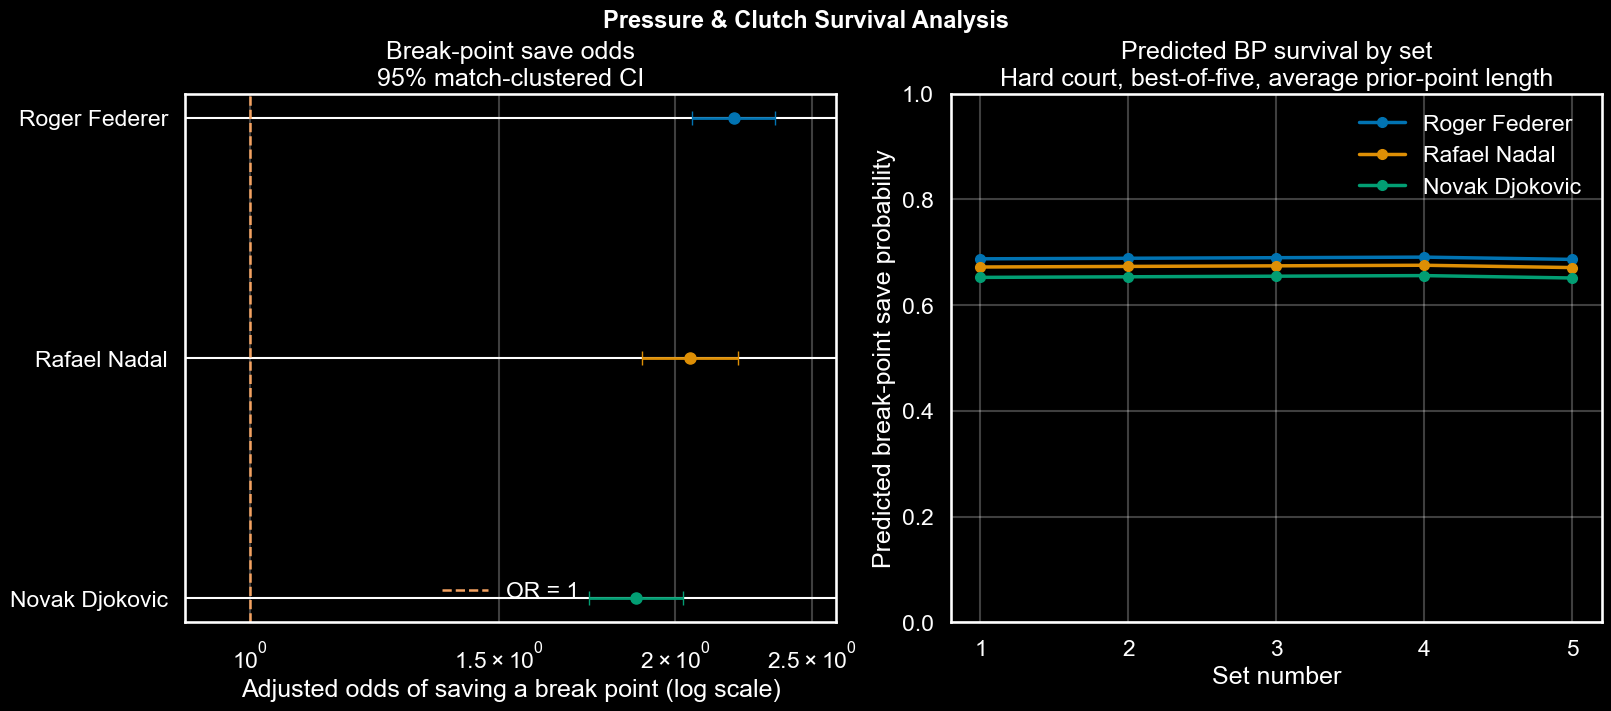

Appended clutch_survival_analysis to goat_web_payload.json without replacing existing keys.


In [66]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression

# Pressure & Clutch Survival Analysis (point-level, 2005 onward).
BIG_THREE_CLUTCH = ["Roger Federer", "Rafael Nadal", "Novak Djokovic"]
SHOT_CODE_CHARS = set("fbrsvzopuylmhijktq")
SURFACE_LEVELS = ["Clay", "Grass", "Hard"]
PLAYER_TERMS = {
    "Roger Federer": "player_federer",
    "Rafael Nadal": "player_nadal",
    "Novak Djokovic": "player_djokovic",
}

# Use the merged report table to define the eligible Big Three match universe.
if "report_tables" in globals() and "master_player_match" in report_tables:
    clutch_master = report_tables["master_player_match"].copy()
elif "master_player_match" in globals():
    clutch_master = master_player_match.copy()
else:
    raise NameError("Run the Data Merging report first to create master_player_match.")

master_required = {"player", "match_id", "match_date"}
missing_master_columns = master_required.difference(clutch_master.columns)
if missing_master_columns:
    raise KeyError(f"master_player_match is missing columns: {sorted(missing_master_columns)}")

def clutch_parse_dates(values):
    date_text = values.astype("string")
    parsed = pd.to_datetime(date_text, format="%Y%m%d", errors="coerce")
    return parsed.fillna(pd.to_datetime(values, errors="coerce"))

clutch_master["match_date"] = clutch_parse_dates(clutch_master["match_date"])
eligible_match_ids = set(
    clutch_master.loc[
        clutch_master["player"].isin(BIG_THREE_CLUTCH)
        & clutch_master["match_date"].ge(pd.Timestamp("2005-01-01")),
        "match_id",
    ].astype(str)
 )
if not eligible_match_ids:
    raise ValueError("No Big Three master-table matches were found from 2005 onward.")

# Use already-loaded sources when available; otherwise load the chart CSVs directly.
clutch_sources = raw_dataframes if "raw_dataframes" in globals() else {}
if "charting_m_matches" in clutch_sources:
    clutch_matches = clutch_sources["charting_m_matches"].copy()
else:
    clutch_matches = pd.read_csv("Raw Data/charting-m-matches.csv", low_memory=False)
point_source_keys = [
    key for key in clutch_sources
    if key.lower().startswith("charting_m_points")
 ]
if point_source_keys:
    clutch_point_frames = [clutch_sources[key].copy() for key in point_source_keys]
else:
    clutch_point_frames = [
        pd.read_csv(path, low_memory=False)
        for path in [
            "Raw Data/charting-m-points-to-2009.csv",
            "Raw Data/charting-m-points-2010s.csv",
            "Raw Data/charting-m-points-2020s.csv",
        ]
    ]

clutch_matches = clutch_matches.rename(
    columns={
        "Player 1": "player1",
        "Player 2": "player2",
        "Date": "match_date",
        "Surface": "surface",
        "Best of": "best_of",
    }
 )
match_required = {"match_id", "player1", "player2", "match_date", "surface", "best_of"}
missing_match_columns = match_required.difference(clutch_matches.columns)
if missing_match_columns:
    raise KeyError(f"Charted match table is missing columns: {sorted(missing_match_columns)}")
clutch_matches["match_id"] = clutch_matches["match_id"].astype(str)
clutch_matches["match_date"] = pd.to_datetime(
    clutch_matches["match_date"].astype("string"), format="%Y%m%d", errors="coerce"
 )
clutch_matches["surface"] = clutch_matches["surface"].astype(str).str.strip().str.title()
clutch_matches["surface"] = clutch_matches["surface"].replace(
    {"Hard Court": "Hard", "Grass Court": "Grass", "Clay Court": "Clay"}
 )
clutch_matches["best_of"] = pd.to_numeric(clutch_matches["best_of"], errors="coerce")
clutch_matches = clutch_matches.drop_duplicates("match_id", keep="first")
clutch_matches = clutch_matches.loc[
    clutch_matches["match_id"].isin(eligible_match_ids)
    & clutch_matches["match_date"].ge(pd.Timestamp("2005-01-01"))
    & (
        clutch_matches["player1"].isin(BIG_THREE_CLUTCH)
        | clutch_matches["player2"].isin(BIG_THREE_CLUTCH)
    )
    & clutch_matches["surface"].isin(SURFACE_LEVELS)
    & clutch_matches["best_of"].isin([3, 5]),
].copy()
if clutch_matches.empty:
    raise ValueError("No eligible Big Three charted matches with supported surfaces and match metadata were found.")

clutch_point_parts = []
for source_number, frame in enumerate(clutch_point_frames):
    required_point_columns = {
        "match_id", "Pt", "Set1", "Set2", "Gm1", "Gm2", "Pts", "Gm#",
        "TbSet", "Svr", "1st", "2nd", "PtWinner",
    }
    missing_point_columns = required_point_columns.difference(frame.columns)
    if missing_point_columns:
        raise KeyError(f"Point table is missing columns: {sorted(missing_point_columns)}")
    frame = frame.copy()
    frame["_source_number"] = source_number
    frame["_source_row"] = np.arange(len(frame))
    clutch_point_parts.append(frame)
clutch_points = pd.concat(clutch_point_parts, ignore_index=True)
clutch_points["match_id"] = clutch_points["match_id"].astype(str)
clutch_points = clutch_points.loc[clutch_points["match_id"].isin(set(clutch_matches["match_id"]))].copy()
for column in ["Pt", "Set1", "Set2", "Gm1", "Gm2", "Svr", "PtWinner"]:
    clutch_points[column] = pd.to_numeric(clutch_points[column], errors="coerce")
clutch_points = clutch_points.dropna(subset=["Pt", "Set1", "Set2", "Svr", "PtWinner"])
clutch_points = clutch_points.sort_values(
    ["match_id", "Pt", "_source_number", "_source_row"], kind="stable"
 ).reset_index(drop=True)
clutch_points = clutch_points.merge(
    clutch_matches[["match_id", "player1", "player2", "match_date", "surface", "best_of"]],
    on="match_id", how="inner", validate="many_to_one"
 )
if clutch_points.empty:
    raise ValueError("No point rows matched the eligible Big Three match universe.")

def clutch_point_shot_count(row):
    first_serve = "" if pd.isna(row["1st"]) else str(row["1st"])
    second_sequence = "" if pd.isna(row["2nd"]) else str(row["2nd"])
    serve_attempts = sum(character in "456" for character in first_serve + second_sequence)
    rally_strokes = sum(character.lower() in SHOT_CODE_CHARS for character in second_sequence)
    return serve_attempts + rally_strokes

clutch_points["_shot_count"] = clutch_points.apply(clutch_point_shot_count, axis=1)
clutch_points["rally_length_prev"] = clutch_points.groupby("match_id", sort=False)["_shot_count"].shift(1).fillna(0)
clutch_points["set_num"] = clutch_points["Set1"] + clutch_points["Set2"] + 1
clutch_points["is_deciding_set"] = clutch_points["set_num"].eq(clutch_points["best_of"]).astype(int)

# Reconstruct tiebreak games using the same score-state rule used elsewhere in this notebook.
game_number = clutch_points["Gm#"].astype(str).str.split("(").str[0].str.strip()
point_score_parts = clutch_points["Pts"].astype(str).str.upper().str.split("-", n=1, expand=True)
score_left_numeric = pd.to_numeric(point_score_parts[0], errors="coerce")
score_right_numeric = pd.to_numeric(point_score_parts[1], errors="coerce")
standard_tennis_scores = {0, 15, 30, 40}
nonstandard_tb_score = (
    score_left_numeric.notna()
    & score_right_numeric.notna()
    & (
        ~score_left_numeric.isin(standard_tennis_scores)
        | ~score_right_numeric.isin(standard_tennis_scores)
    )
 )
tb_set_flag = clutch_points["TbSet"].astype(str).str.strip().str.lower().isin(["true", "1", "yes"])
tb_candidate = (
    tb_set_flag
    & clutch_points["Gm1"].eq(clutch_points["Gm2"])
    & clutch_points["Gm1"].ge(3)
    & nonstandard_tb_score
 )
tb_group_columns = ["match_id", "Set1", "Set2"]
clutch_points["_game_number"] = game_number
tb_group_columns.append("_game_number")
tb_candidate_keys = clutch_points.loc[tb_candidate, tb_group_columns].drop_duplicates()
if tb_candidate_keys.empty:
    raise ValueError("No tiebreak point groups were reconstructed from the available charted score states.")
candidate_index = pd.MultiIndex.from_frame(tb_candidate_keys)
point_index = pd.MultiIndex.from_frame(clutch_points[tb_group_columns])
clutch_points["is_tiebreak_point"] = point_index.isin(candidate_index)

# Break points are identified from the receiver's pre-point game score; the server is the player facing the point.
score_rank = {"0": 0, "15": 1, "30": 2, "40": 3, "AD": 4}
score_left = point_score_parts[0].astype(str).str.strip().map(score_rank)
score_right = point_score_parts[1].astype(str).str.strip().map(score_rank)
server_score = np.where(clutch_points["Svr"].eq(1), score_left, score_right)
receiver_score = np.where(clutch_points["Svr"].eq(1), score_right, score_left)
server_name = np.where(clutch_points["Svr"].eq(1), clutch_points["player1"], clutch_points["player2"])
is_break_point = (
    pd.notna(server_score)
    & pd.notna(receiver_score)
    & (np.asarray(receiver_score) >= 3)
    & (np.asarray(receiver_score) > np.asarray(server_score))
    & ~clutch_points["is_tiebreak_point"].to_numpy()
 )
bp_points = clutch_points.loc[is_break_point].copy()
bp_points["player"] = np.asarray(server_name)[is_break_point]
bp_points["clutch_success"] = (bp_points["PtWinner"] == bp_points["Svr"]).astype(int)
bp_points["is_tiebreak_point"] = 0
bp_events = bp_points.loc[bp_points["player"].isin(BIG_THREE_CLUTCH)].copy()

# A tiebreak point contributes one player-observation for each Big Three participant.
tb_event_parts = []
for player_number, player_column in [(1, "player1"), (2, "player2")]:
    player_points = clutch_points.loc[
        clutch_points["is_tiebreak_point"] & clutch_points[player_column].isin(BIG_THREE_CLUTCH)
    ].copy()
    player_points["player"] = player_points[player_column]
    player_points["clutch_success"] = (player_points["PtWinner"] == player_number).astype(int)
    tb_event_parts.append(player_points)
tb_events = pd.concat(tb_event_parts, ignore_index=True) if tb_event_parts else pd.DataFrame()
pressure_events = pd.concat([bp_events, tb_events], ignore_index=True)
if pressure_events.empty or pressure_events["clutch_success"].nunique() != 2:
    raise ValueError("The reconstructed pressure-point sample is empty or contains only one outcome class.")
pressure_events["is_tiebreak_point"] = pressure_events["is_tiebreak_point"].astype(int)
pressure_events["set_num"] = pd.to_numeric(pressure_events["set_num"], errors="coerce")
pressure_events["rally_length_prev"] = pd.to_numeric(pressure_events["rally_length_prev"], errors="coerce")
pressure_events = pressure_events.dropna(
    subset=["player", "surface", "set_num", "rally_length_prev", "is_deciding_set", "is_tiebreak_point", "clutch_success", "match_id"]
 ).copy()
if pressure_events["player"].nunique() != 3:
    raise ValueError(f"Expected observations for all three players; found {sorted(pressure_events['player'].unique())}.")
bp_counts = bp_events.groupby("player").size().reindex(BIG_THREE_CLUTCH, fill_value=0)
tb_counts = tb_events.groupby("player").size().reindex(BIG_THREE_CLUTCH, fill_value=0)
if (bp_counts == 0).any() or (tb_counts == 0).any():
    raise ValueError(f"Insufficient event coverage by player. Break points: {bp_counts.to_dict()}; tiebreak points: {tb_counts.to_dict()}.")

# Full player indicators are used without a global intercept, so each player coefficient is an adjusted BP-save log-odds.
model_events = pressure_events.reset_index(drop=True)
feature_columns = []
design = pd.DataFrame(index=model_events.index)
for player, term in PLAYER_TERMS.items():
    design[term] = model_events["player"].eq(player).astype(float)
    tb_term = f"{term}_tiebreak_interaction"
    design[tb_term] = design[term] * model_events["is_tiebreak_point"]
    feature_columns.extend([term, tb_term])
design["surface_clay"] = model_events["surface"].eq("Clay").astype(float)
design["surface_grass"] = model_events["surface"].eq("Grass").astype(float)
design["set_num_after_set_1"] = model_events["set_num"] - 1
rally_reference = float(model_events["rally_length_prev"].mean())
design["rally_length_prev_centered"] = model_events["rally_length_prev"] - rally_reference
design["is_deciding_set"] = model_events["is_deciding_set"].astype(float)
feature_columns.extend([
    "surface_clay", "surface_grass", "set_num_after_set_1",
    "rally_length_prev_centered", "is_deciding_set",
 ])
design = design[feature_columns].astype(float)
if np.linalg.matrix_rank(design.to_numpy()) < design.shape[1]:
    raise ValueError("The clutch model design matrix is rank-deficient; one or more requested effects cannot be estimated from this sample.")

clutch_model = LogisticRegression(
    penalty=None, solver="lbfgs", fit_intercept=False, max_iter=2000, tol=1e-10,
 )
clutch_model.fit(design, model_events["clutch_success"].astype(int))
if int(clutch_model.n_iter_[0]) >= 2000:
    raise RuntimeError("The clutch logistic regression did not converge; inspect sample separation or reduce unsupported terms.")
beta_values = clutch_model.coef_[0]
predicted_training_probability = clutch_model.predict_proba(design)[:, 1]
training_outcome = model_events["clutch_success"].to_numpy(dtype=float)
information_weights = predicted_training_probability * (1 - predicted_training_probability)
weighted_design = design.to_numpy() * information_weights[:, None]
bread = np.linalg.pinv(design.to_numpy().T @ weighted_design)
individual_scores = design.to_numpy() * (training_outcome - predicted_training_probability)[:, None]
score_columns = [f"score_{index}" for index in range(design.shape[1])]
score_frame = pd.DataFrame(individual_scores, columns=score_columns)
score_frame["match_id"] = model_events["match_id"].to_numpy()
cluster_scores = score_frame.groupby("match_id", sort=False)[score_columns].sum().to_numpy()
match_cluster_count = cluster_scores.shape[0]
sample_count, parameter_count = design.shape
if match_cluster_count < 2 or sample_count <= parameter_count:
    raise ValueError("Too few independent match clusters for clustered odds-ratio inference.")
meat = cluster_scores.T @ cluster_scores
finite_sample_correction = (match_cluster_count / (match_cluster_count - 1)) * ((sample_count - 1) / (sample_count - parameter_count))
cluster_covariance = finite_sample_correction * bread @ meat @ bread
standard_errors = np.sqrt(np.clip(np.diag(cluster_covariance), 0, None))
if not np.isfinite(standard_errors).all() or (standard_errors <= 0).any():
    raise RuntimeError("Cluster-robust standard errors were not finite and positive; odds-ratio inference is unavailable.")
z_statistics = beta_values / standard_errors
p_values = 2 * stats.norm.sf(np.abs(z_statistics))
critical_value = stats.norm.ppf(0.975)

coefficient_labels = {
    **{term: f"Break-point save odds: {player}" for player, term in PLAYER_TERMS.items()},
    **{f"{term}_tiebreak_interaction": f"Tiebreak-specific odds shift: {player}" for player, term in PLAYER_TERMS.items()},
    "surface_clay": "Clay vs Hard surface",
    "surface_grass": "Grass vs Hard surface",
    "set_num_after_set_1": "Each additional set (vs set 1)",
    "rally_length_prev_centered": "Each additional shot in preceding point",
    "is_deciding_set": "Deciding vs non-deciding set",
}
coefficient_rows = []
for index, term in enumerate(feature_columns):
    beta = float(beta_values[index])
    standard_error = float(standard_errors[index])
    p_value = float(p_values[index])
    coefficient_rows.append(
        {
            "Variable / Player": coefficient_labels[term],
            "Coefficient (beta)": beta,
            "Odds Ratio": float(np.exp(beta)),
            "95% CI Lower": float(np.exp(beta - critical_value * standard_error)),
            "95% CI Upper": float(np.exp(beta + critical_value * standard_error)),
            "p-value": p_value,
            "Significant (p < 0.05)": bool(p_value < 0.05),
            "_term": term,
        }
    )
clutch_odds_summary = pd.DataFrame(coefficient_rows)
clutch_display = clutch_odds_summary.drop(columns="_term").copy()
clutch_display["p-value"] = clutch_display["p-value"].map(lambda value: f"{value:.3g}")
display(clutch_display.round({"Coefficient (beta)": 4, "Odds Ratio": 4, "95% CI Lower": 4, "95% CI Upper": 4}))

# Publication-style panels: adjusted BP-save odds and predicted probability by set in a best-of-five reference match.
plt.style.use("dark_background")
sns.set_palette("colorblind")
player_colors = dict(zip(BIG_THREE_CLUTCH, sns.color_palette("colorblind", n_colors=3)))
player_effects = clutch_odds_summary[
    clutch_odds_summary["_term"].isin(PLAYER_TERMS.values())
].copy()
player_effects["Player"] = player_effects["_term"].map({term: player for player, term in PLAYER_TERMS.items()})
player_effects["Player"] = pd.Categorical(player_effects["Player"], categories=BIG_THREE_CLUTCH, ordered=True)
player_effects = player_effects.sort_values("Player")
figure, (forest_ax, probability_ax) = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
forest_positions = np.arange(len(player_effects))
for position, (_, effect) in enumerate(player_effects.iterrows()):
    player_name = str(effect["Player"])
    forest_ax.errorbar(
        effect["Odds Ratio"], position,
        xerr=[[effect["Odds Ratio"] - effect["95% CI Lower"]], [effect["95% CI Upper"] - effect["Odds Ratio"]]],
        fmt="o", color=player_colors[player_name], ecolor=player_colors[player_name],
        elinewidth=2, capsize=5, markersize=8,
    )
forest_ax.axvline(1.0, color="#F4A261", linestyle="--", linewidth=1.8, label="OR = 1")
forest_ax.set_xscale("log")
forest_ax.set_xlim(0.9, 2.6)
forest_ax.set_xticks([1.0, 1.5, 2.0, 2.5])
forest_ax.minorticks_off()
forest_ax.set_yticks(forest_positions, player_effects["Player"].astype(str))
forest_ax.invert_yaxis()
forest_ax.set_xlabel("Adjusted odds of saving a break point (log scale)")
forest_ax.set_title("Break-point save odds\n95% match-clustered CI")
forest_ax.legend(frameon=False, loc="best")
forest_ax.grid(True, axis="x", alpha=0.25)

prediction_rows = []
for player in BIG_THREE_CLUTCH:
    for set_number in range(1, 6):
        row = {column: 0.0 for column in feature_columns}
        row[PLAYER_TERMS[player]] = 1.0
        row["set_num_after_set_1"] = float(set_number - 1)
        row["rally_length_prev_centered"] = 0.0
        row["is_deciding_set"] = float(set_number == 5)
        prediction_rows.append({"player": player, "set_num": set_number, **row})
prediction_frame = pd.DataFrame(prediction_rows)
prediction_design = prediction_frame[feature_columns].astype(float)
prediction_frame["predicted_bp_save_probability"] = clutch_model.predict_proba(prediction_design)[:, 1]
for player in BIG_THREE_CLUTCH:
    player_prediction = prediction_frame[prediction_frame["player"] == player]
    probability_ax.plot(
        player_prediction["set_num"],
        player_prediction["predicted_bp_save_probability"],
        marker="o", linewidth=2.5, markersize=7,
        color=player_colors[player], label=player,
    )
probability_ax.set_xticks(range(1, 6))
probability_ax.set_ylim(0, 1)
probability_ax.set_xlabel("Set number")
probability_ax.set_ylabel("Predicted break-point save probability")
probability_ax.set_title("Predicted BP survival by set\nHard court, best-of-five, average prior-point length")
probability_ax.legend(frameon=False, loc="best")
probability_ax.grid(True, alpha=0.25)
figure.suptitle("Pressure & Clutch Survival Analysis", fontsize=17, fontweight="bold")
plt.show()

# Append inference and event coverage while retaining every existing payload section.
clutch_payload_path = "goat_web_payload.json"
try:
    with open(clutch_payload_path, "r", encoding="utf-8") as payload_file:
        clutch_payload = json.load(payload_file)
except FileNotFoundError:
    clutch_payload = {}

def clutch_json_safe(value):
    if isinstance(value, dict):
        return {str(key): clutch_json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [clutch_json_safe(item) for item in value]
    if pd.isna(value):
        return None
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    return value

summary_for_payload = clutch_odds_summary.drop(columns="_term").to_dict(orient="records")
event_coverage = {
    player: {
        "break_points_faced": int(bp_counts[player]),
        "tiebreak_points_observed": int(tb_counts[player]),
    }
    for player in BIG_THREE_CLUTCH
}
clutch_payload["clutch_survival_analysis"] = {
    "method": "Pooled point-level logistic regression with player fixed effects, player-specific tiebreak effects, and match-clustered sandwich standard errors.",
    "period": "2005 onward, restricted to charted matches represented in master_player_match.",
    "outcomes": {
        "break_point": "Server wins the point while facing a reconstructed break point.",
        "tiebreak_point": "Player wins the point in a reconstructed tiebreak; each point contributes one row per Big Three participant.",
    },
    "inference": "Odds ratios and 95% Wald confidence intervals use match-clustered standard errors; player break-point odds are conditional on Hard court, set 1, average preceding-point shot count, and non-deciding set.",
    "prediction_profile": "Best-of-five Hard-court match; average preceding-point shot count; deciding-set indicator is set only in set 5.",
    "feature_reference": {
        "surface": "Hard",
        "set_num": "Set 1",
        "rally_length_prev": float(rally_reference),
        "standard_error_clustering": "match_id",
    },
    "event_coverage": event_coverage,
    "model_observations": int(len(model_events)),
    "model_coefficients": clutch_json_safe(summary_for_payload),
}
with open(clutch_payload_path, "w", encoding="utf-8") as payload_file:
    json.dump(clutch_json_safe(clutch_payload), payload_file, indent=2, allow_nan=False)
print(f"Appended clutch_survival_analysis to {clutch_payload_path} without replacing existing keys.")

### Reading the Results
The left-hand chart shows each player’s fitted break-point-save odds under the same reference conditions: a hard court, the first set, an average-length preceding point, and a non-deciding set. Here, odds mean saves compared with failures: Federer’s 2.20 is about 2.2 saves per failure, or roughly a 69% save probability; Nadal’s 2.05 is about 67%, and Djokovic’s 1.88 is about 65%. The dashed line at 1 marks even odds (50/50), not a direct Federer-versus-Nadal comparison. Each confidence interval is above that line, but the intervals overlap, so the model does not establish a clear difference between the players.

The right-hand chart shows predicted break-point-save probability by set for a best-of-five hard-court match, with the preceding-point length held at its sample average. The lines are close together and nearly flat across sets, suggesting set number and the deciding-set flag made little difference to the predictions in this sample. The table also reports tiebreak-point estimates, which describe winning a tiebreak point, a different outcome from saving a break point. These results cover charted matches from 2005 onward: useful as a snapshot of recorded play, but not a definitive ranking of nerve or proof that any factor caused success.